## Hydrodynamic model of the Southern North Sea

In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
import mikeio
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import modelskill as ms
import torch

# dataset helper
from helper import get_altimetry_obs, get_wl_point_obs
from helper import plot_shred_reconstruction, extract_water_level_measurements

import sys
from pathlib import Path

# Add parent directory to path to access src module
sys.path.insert(0, str(Path.cwd().parent.parent))

from src.datamanager import DataManager
from src.engine import SHREDEngine
from src.train import fit, evaluate
from src.mSHRED.mSRED import mSHRED

# get device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


## Load Data and Measurement

In [4]:
# folders
dfs_fldr = "datasets/output/Area.dfsu"
msh_fldr = "datasets/input/Mesh_8000_elems_HD_v2.mesh"
obs_fldr  = "datasets/observations/"

msh = mikeio.open(msh_fldr)
dfs = mikeio.open(dfs_fldr)

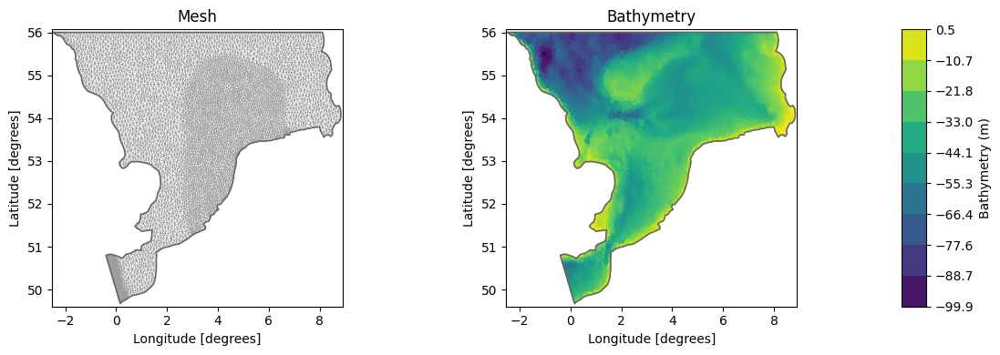

In [5]:
# plot geometry
geom = dfs.geometry

fig, axs = plt.subplots(1,2, figsize = (12,4))
geom.plot.mesh(ax=axs[0])
geom.plot(ax=axs[1])
plt.tight_layout()
plt.show()

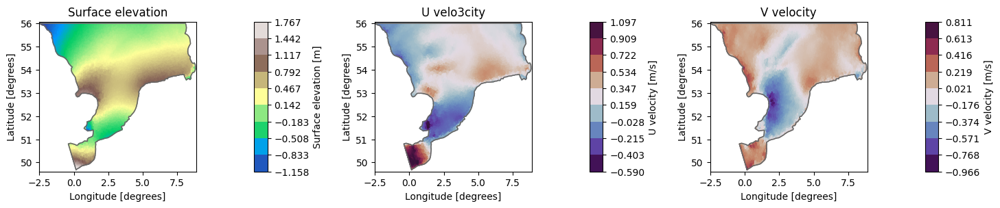

In [6]:
# plot a simulation
ds = dfs.read()

dsH = ds["Surface elevation"]
dsU = ds["U velocity"]
dsV = ds["V velocity"]

plot_time = ds.time[-1]
fig,axs = plt.subplots(1, 3, figsize=(15,5))
dsH.sel(time=plot_time).plot(ax=axs[0], title="Surface elevation", cmap = "terrain")
dsU.sel(time=plot_time).plot(ax=axs[1], title="U velo3city", cmap = "twilight_shifted")
dsV.sel(time=plot_time).plot(ax=axs[2], title="V velocity", cmap = "twilight_shifted")
plt.tight_layout()
plt.show()


## Available Sensors

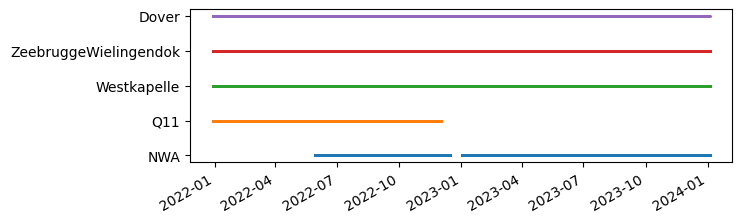

In [7]:
# sensor coverage

wllist = get_wl_point_obs()
#altlist = get_altimetry_obs()

high_fidelity = ["Dover", "ZeebruggeWielingendok", "Westkapelle", "NWA", "Q11"]

alllist = wllist #+ altlist
alllist = [obs for obs in alllist if obs.name in high_fidelity]
ms.plotting.temporal_coverage(alllist)
plt.show()

Total stations: 5
Stations with full temporal coverage: 2
Intermittent stations: 3


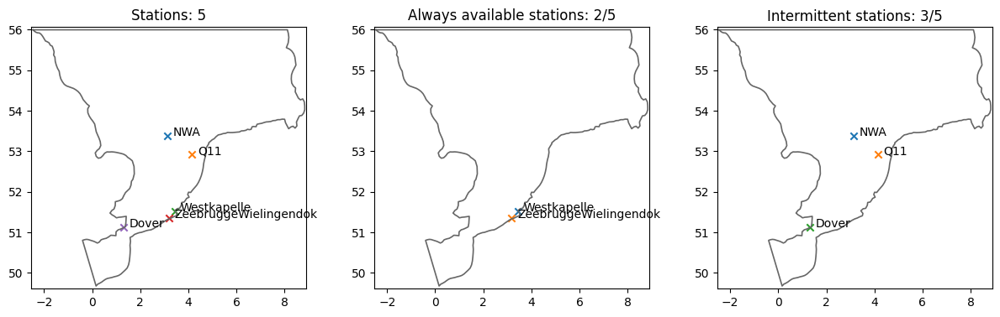

In [8]:
# Select stations with full temporal coverage

stations = []
availables = []
intermittent = []
for i in range(len(alllist)):
    stations.append(alllist[i])
    if ds.time.isin(alllist[i].time).all():
        availables.append(alllist[i])
    else:
        intermittent.append(alllist[i])

print(f"Total stations: {len(stations)}")
print(f"Stations with full temporal coverage: {len(availables)}")
print(f"Intermittent stations: {len(intermittent)}")

fig, axs = plt.subplots(1,3, figsize = (12,4))
ms.plotting.spatial_overview(stations, mod = msh.geometry, figsize = (5,5), ax=axs[0], title=f"Stations: {len(stations)}")
ms.plotting.spatial_overview(availables, mod = msh.geometry, figsize = (5,5), ax=axs[1], title=f"Always available stations: {len(availables)}/{len(stations)}")
ms.plotting.spatial_overview(intermittent, mod = msh.geometry, figsize = (5,5), ax=axs[2], title=f"Intermittent stations: {len(intermittent)}/{len(stations)}")

plt.tight_layout()
plt.show()


In [9]:
# Extract water level measurements

measurements = extract_water_level_measurements(stations, ds_time=ds.time, obs_fldr=obs_fldr)

In [10]:
# Extract the values and convert to torch tensors

# remove nans from H, U, V 
dsH = dsH.values[:,~np.isnan(ds["Surface elevation"].values).any(axis=0)]
dsU = dsU.values[:,~np.isnan(ds["Surface elevation"].values).any(axis=0)]
dsV = dsV.values[:,~np.isnan(ds["Surface elevation"].values).any(axis=0)]

# outputs
H = torch.tensor(dsH, dtype=torch.float32)
U = torch.tensor(dsU, dtype=torch.float32)
V = torch.tensor(dsV, dtype=torch.float32)

# inputs
measurements = torch.tensor(measurements, dtype=torch.float32)

# print the shape of the arrays
print("H shape:", H.shape)
print("U shape:", U.shape)
print("V shape:", V.shape)
print("Measurements shape:", measurements.shape)

# free memory
del dsH, dsU, dsV

H shape: torch.Size([35039, 8532])
U shape: torch.Size([35039, 8532])
V shape: torch.Size([35039, 8532])
Measurements shape: torch.Size([35039, 5])


In [11]:
ERRORS = []

In [12]:
# Extract measurements for always-available stations only
av_indices = [stations.index(s) for s in availables]
measurements_av = measurements[:, av_indices]

time_steps, _ = measurements_av.shape

# Count NaNs for intermittent stations
intermittent_indices = [stations.index(s) for s in intermittent]
nan_counts_intermittent = np.isnan(measurements[:, intermittent_indices].numpy()).sum(axis=0)

# Build a clean coverage table and sort by coverage percentage
rows = []
for i, s in enumerate(intermittent):
    ok_count = int(time_steps - nan_counts_intermittent[i])
    nan_count = int(nan_counts_intermittent[i])
    coverage = 100 * ok_count / time_steps
    rows.append({
        "station": s.name,
        "ok": ok_count,
        "nans": nan_count,
        "coverage_%": round(coverage, 1),
    })
coverage_df = pd.DataFrame(rows).sort_values("coverage_%", ascending=False).reset_index(drop=True)

print(f"Intermittent stations ({len(intermittent)}):")
display(coverage_df.style.format({"ok": "{:,}", "nans": "{:,}", "coverage_%": "{:.1f}"}))

Intermittent stations (3):


,station,ok,nans,coverage_%
0,NWA,"26,469","8,570",75.5
1,Dover,"17,024","18,015",48.6
2,Q11,"15,900","19,139",45.4


## Idea T.0: Only Available Sensors

In [12]:
# Keep only sensors that never contain NaNs over time
nan_sensor_mask = torch.isnan(measurements).any(dim=0)
measurements_av = measurements[:, ~nan_sensor_mask]

kept_sensor_indices = torch.where(~nan_sensor_mask)[0]
removed_sensor_indices = torch.where(nan_sensor_mask)[0]

# print the shape of the arrays
print("\nAfter selecting always-available stations only:")
print("H shape:", H.shape)
print("U shape:", U.shape)
print("V shape:", V.shape)
print("Measurements shape:", measurements_av.shape)


After selecting always-available stations only:
H shape: torch.Size([35039, 8532])
U shape: torch.Size([35039, 8532])
V shape: torch.Size([35039, 8532])
Measurements shape: torch.Size([35039, 2])


Nuber of nan values in measurements after imputation: 0 



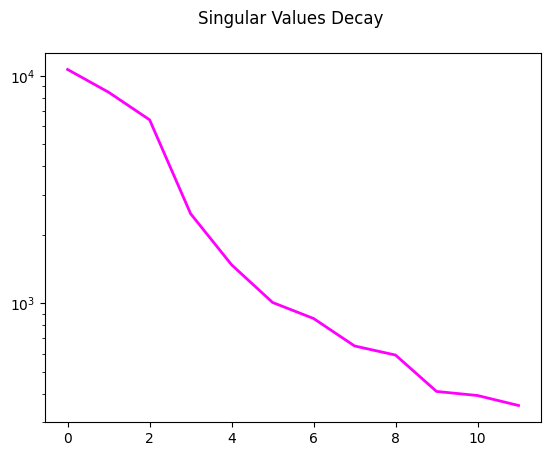

Residual energy of Surface elevation after keeping 12 modes: 0.1678 %


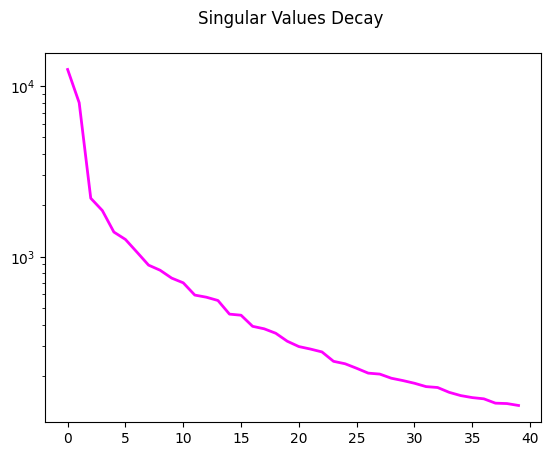

Residual energy of U velocity after keeping 40 modes: 0.1947 %


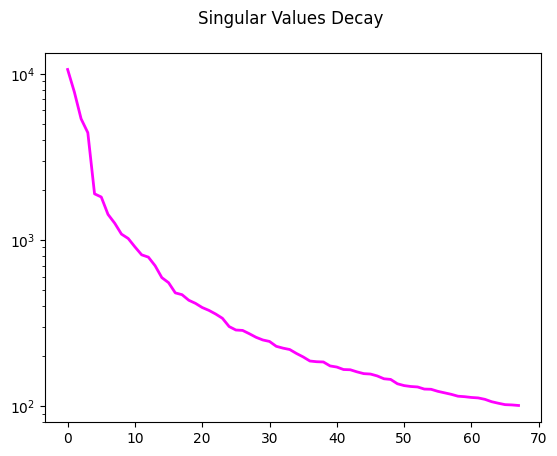

Residual energy of V velocity after keeping 68 modes: 0.1872 %

Datasets: ['Surface elevation', 'U velocity', 'V velocity']

Number of nan values in sensor measurements after masking: 0

Data shapes after preparation:
Train:	 torch.Size([28031, 24, 2]) -> torch.Size([28031, 120])
Val:	 torch.Size([3504, 24, 2]) -> torch.Size([3504, 120])
Test:	 torch.Size([3504, 24, 2]) -> torch.Size([3504, 120])

Input shape for the model: 2
Output shape for the model: 120


In [13]:

# Data manager

lags = 24
manager = DataManager(lags = lags, train_size = 0.8, val_size = 0.1, test_size = 0.1)

# add data to manager
manager.add_data(H, id = "Surface elevation" , compress = 12, measurements = measurements_av, verbose = True)
manager.add_data(U, id = "U velocity", compress = 40, verbose = True)
manager.add_data(V, id = "V velocity", compress = 68, verbose = True)

# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare(verbose = True)

# output shape is the compressed (SVD) dimension, not the raw spatial size
nn_input_shape = measurements_av.shape[1]
nn_output_shape = manager.data.shape[1]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)


Starting training...


Training: 100%|██████████| 200/200 [30:20<00:00,  9.10s/it, Train Loss=0.0046, Val Loss=0.0047, Patience=30, Best Val Loss=0.0046, LR=0.00e+00]

Training completed with best validation loss: 0.0046


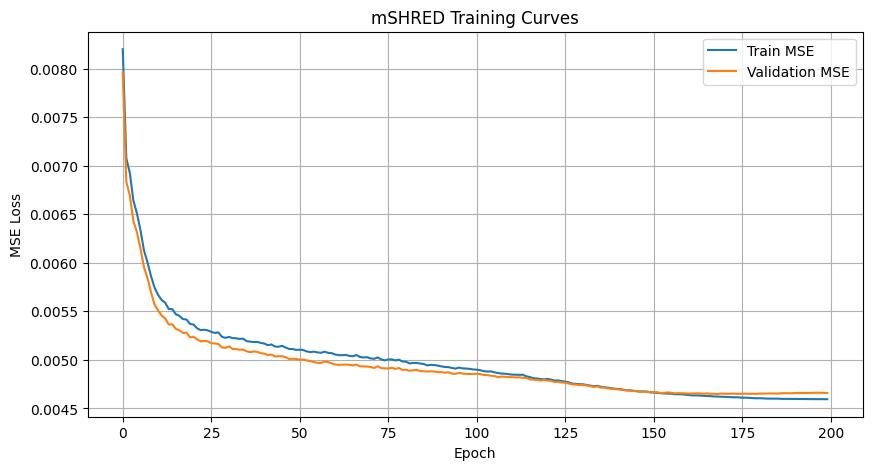

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + MLP,(T.0) only available sensors,0.004597,0.004661,0.011176,0.134996,0.134242,0.207774


In [14]:

# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer",
    encoder_depth=2,
    input_size=nn_input_shape,
    n_heads=4,
    dim_feedforward=64,
    hidden_size=32,
    input_length=lags,

    # Decoder
    decoder="mlp",
    decoder_hidden_sizes=[64],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
    double_channels = False
)

mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=200,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=200,
    patience=60,
    verbose=True,
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors, label='Train MSE')
plt.plot(valid_errors, label='Validation MSE')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED Training Curves')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse, train_mre = evaluate(mshred, train_dataset)
val_mse, val_mre = evaluate(mshred, val_dataset)
test_mse, test_mre = evaluate(mshred, test_dataset)
test_error = {
    "model": f"(mSHRED): TR + MLP",
    "type" : "(T.0) only available sensors",
    "train-mse": float(train_mse),
    "val-mse": float(val_mse),
    "test-mse": float(test_mse),
    "train-mre": float(train_mre),
    "val-mre": float(val_mre),
    "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_T_0_only_available_sensors.png


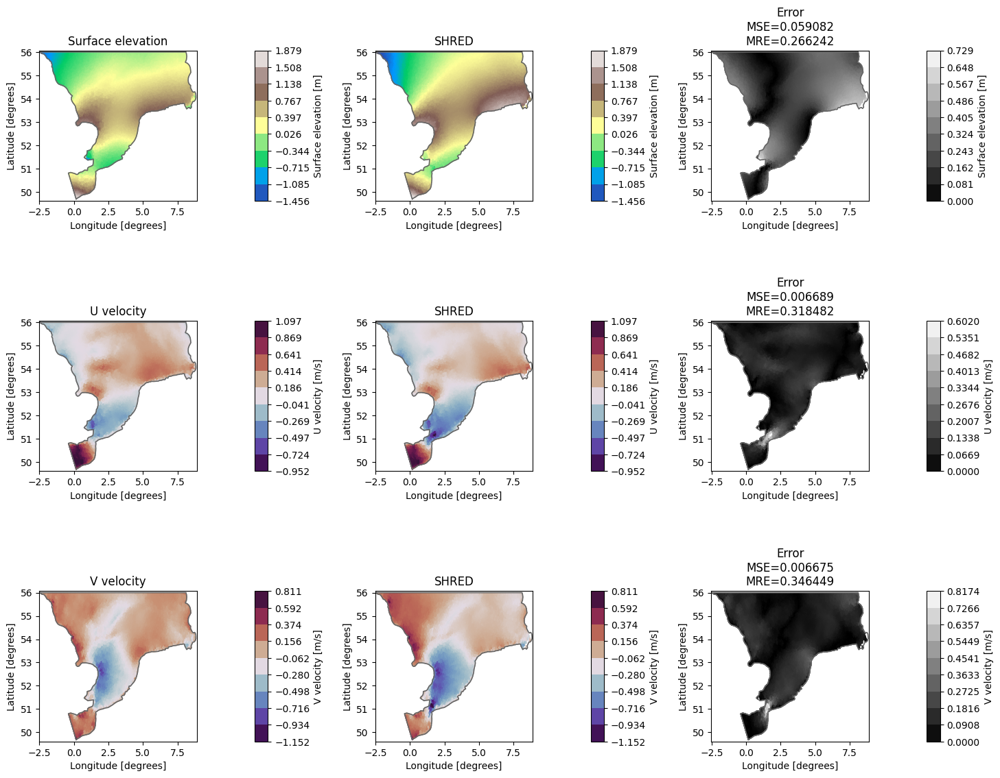

In [15]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="T_0_only_available_sensors")

del engine, test_reconstruction, ds_shred, ds_error, mshred

## Idea S.0: Only Available Sensors

Starting training...


Training:   0%|          | 0/200 [00:00<?, ?it/s]

Training: 100%|██████████| 200/200 [09:34<00:00,  2.87s/it, Train Loss=0.0044, Val Loss=0.0045, Patience=15, Best Val Loss=0.0045, LR=0.00e+00]

Training completed with best validation loss: 0.0045


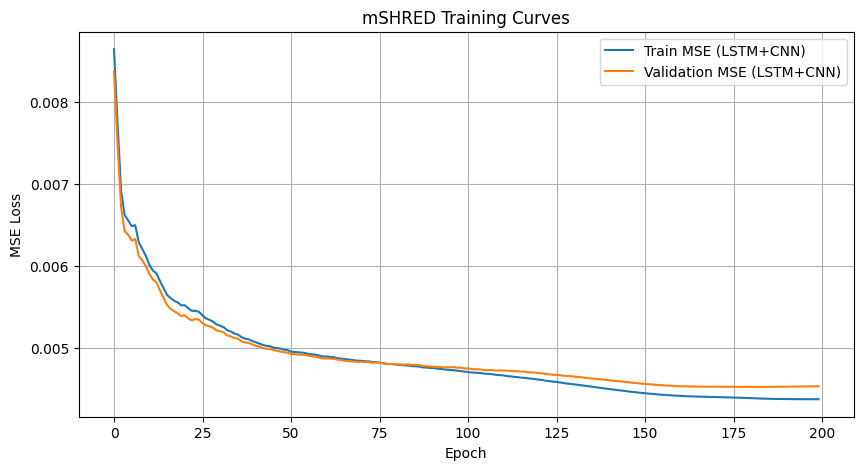

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + MLP,(T.0) only available sensors,0.004597,0.004661,0.011176,0.134996,0.134242,0.207774
1,(mSHRED) LSTM + CNN,(S.0) only available sensors,0.004379,0.004537,0.010846,0.131545,0.132755,0.204939


In [16]:

# mSHRED TRAINING (Idea S.0) - LSTM + CNN
model_args_s0 = dict(
    # Encoder
    encoder="lstm",
    input_size=nn_input_shape,
    hidden_size=32,
    num_layers=2,

    # Decoder
    decoder="mlp",
    decoder_hidden_sizes=[64],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
)

mshred = mSHRED(args=model_args_s0).to(device)

train_errors_shred, valid_errors_shred = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=200,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=200,
    patience=60,
    verbose=True,
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors_shred, label='Train MSE (LSTM+CNN)')
plt.plot(valid_errors_shred, label='Validation MSE (LSTM+CNN)')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED Training Curves')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse_shred, train_mre_shred = evaluate(mshred, train_dataset)
val_mse_shred, val_mre_shred = evaluate(mshred, val_dataset)
test_mse_shred, test_mre_shred = evaluate(mshred, test_dataset)
test_error = {
    "model": "(mSHRED) LSTM + CNN",
    "type": "(S.0) only available sensors",
    "train-mse": float(train_mse_shred),
    "val-mse": float(val_mse_shred),
    "test-mse": float(test_mse_shred),
    "train-mre": float(train_mre_shred),
    "val-mre": float(val_mre_shred),
    "test-mre": float(test_mre_shred),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_S_0_only_available_sensors.png


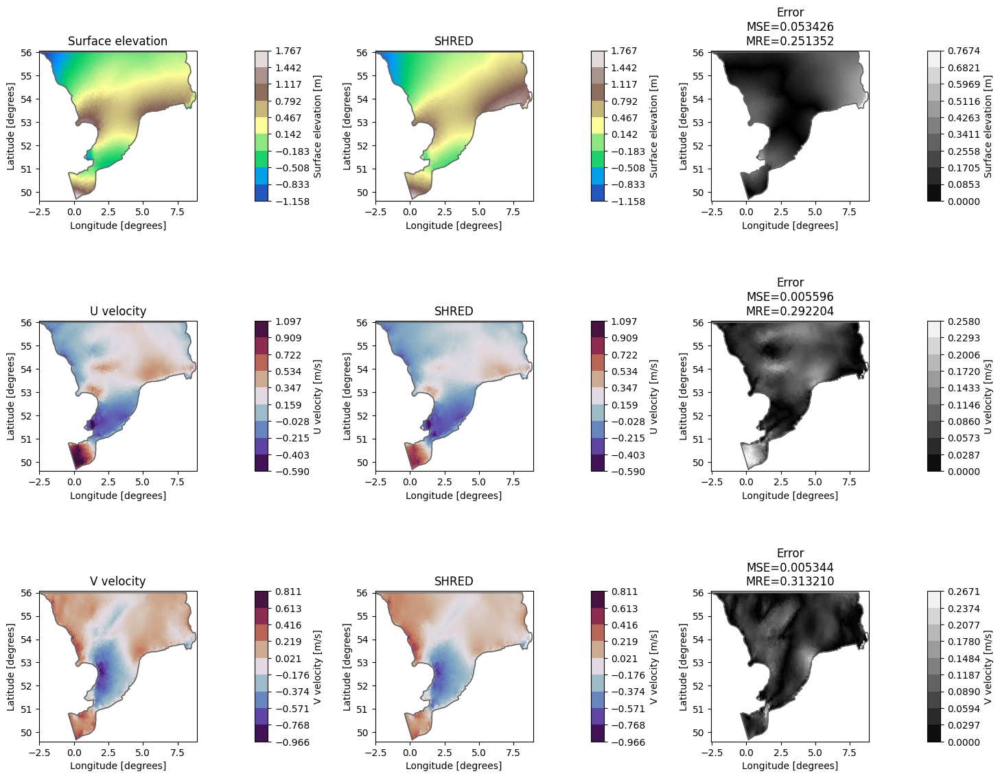

In [17]:

# SHRED RECONSTRUCTION (Idea S.0)
engine_shred = SHREDEngine(manager, mshred)
test_reconstruction_shred = engine_shred.sensor_to_reconstruction_dataset(test_dataset)
ds_shred_s0, ds_error_s0 = plot_shred_reconstruction(test_reconstruction_shred, ds, geom, title_suffix="S_0_only_available_sensors")

del engine_shred, test_reconstruction_shred, ds_shred_s0, ds_error_s0, mshred, manager


## Idea T.1.A: Median imputer

In [18]:

# Data manager

lags = 24
manager = DataManager(lags = lags, train_size = 0.8, val_size = 0.1, test_size = 0.1)

# add data to manager
manager.add_data(
    H, id = "Surface elevation" , compress = 12, 
    measurements = measurements, imputer="median"
)
manager.add_data(U, id = "U velocity", compress = 40)
manager.add_data(V, id = "V velocity", compress = 68)

# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare(verbose = True)

# output shape is the compressed (SVD) dimension, not the raw spatial size
nn_input_shape = measurements.shape[1]
nn_output_shape = manager.data.shape[1]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)


Nuber of nan values in measurements after imputation: 0 

Residual energy of Surface elevation after keeping 12 modes: 0.1678 %
Residual energy of U velocity after keeping 40 modes: 0.1947 %
Residual energy of V velocity after keeping 68 modes: 0.1872 %

Datasets: ['Surface elevation', 'U velocity', 'V velocity']

Number of nan values in sensor measurements after masking: 0

Data shapes after preparation:
Train:	 torch.Size([28031, 24, 5]) -> torch.Size([28031, 120])
Val:	 torch.Size([3504, 24, 5]) -> torch.Size([3504, 120])
Test:	 torch.Size([3504, 24, 5]) -> torch.Size([3504, 120])

Input shape for the model: 5
Output shape for the model: 120


Starting training...


Training: 100%|██████████| 200/200 [27:55<00:00,  8.38s/it, Train Loss=0.0044, Val Loss=0.0046, Patience=5, Best Val Loss=0.0046, LR=0.00e+00]

Training completed with best validation loss: 0.0046


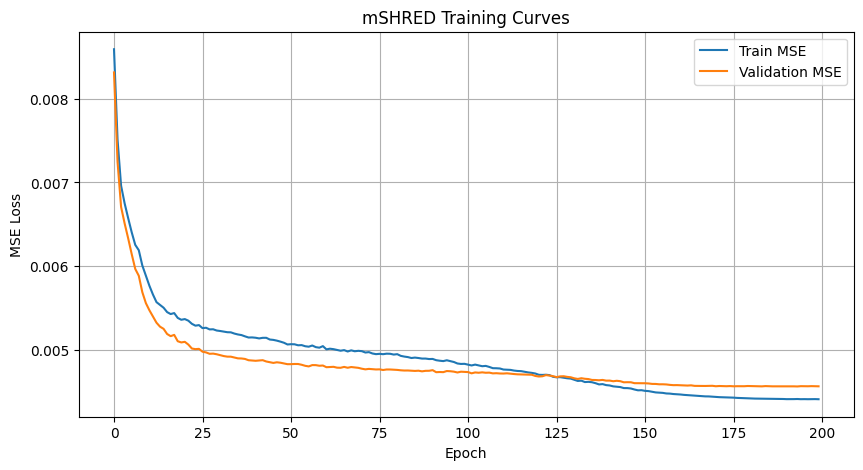

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + MLP,(T.0) only available sensors,0.004597,0.004661,0.011176,0.134996,0.134242,0.207774
1,(mSHRED) LSTM + CNN,(S.0) only available sensors,0.004379,0.004537,0.010846,0.131545,0.132755,0.204939
2,(mSHRED): TR + MLP,(T.1.A) median imputation for missing sensors,0.004416,0.004570,0.010951,0.132860,0.133064,0.206131


In [19]:

# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer",
    encoder_depth=2,
    input_size=nn_input_shape,
    n_heads=4,
    dim_feedforward=64,
    hidden_size=32,
    input_length=lags,

    # Decoder
    decoder="mlp",
    decoder_hidden_sizes=[64],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
    double_channels=False,
)

mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=200,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=200,
    patience=60,
    verbose=True,
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors, label='Train MSE')
plt.plot(valid_errors, label='Validation MSE')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED Training Curves')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse, train_mre = evaluate(mshred, train_dataset)
val_mse, val_mre = evaluate(mshred, val_dataset)
test_mse, test_mre = evaluate(mshred, test_dataset)
test_error = {
    "model": f"(mSHRED): TR + MLP",
    "type" : "(T.1.A) median imputation for missing sensors",
    "train-mse": float(train_mse),
    "val-mse": float(val_mse),
    "test-mse": float(test_mse),
    "train-mre": float(train_mre),
    "val-mre": float(val_mre),
    "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_T_1_A_median_imputation.png


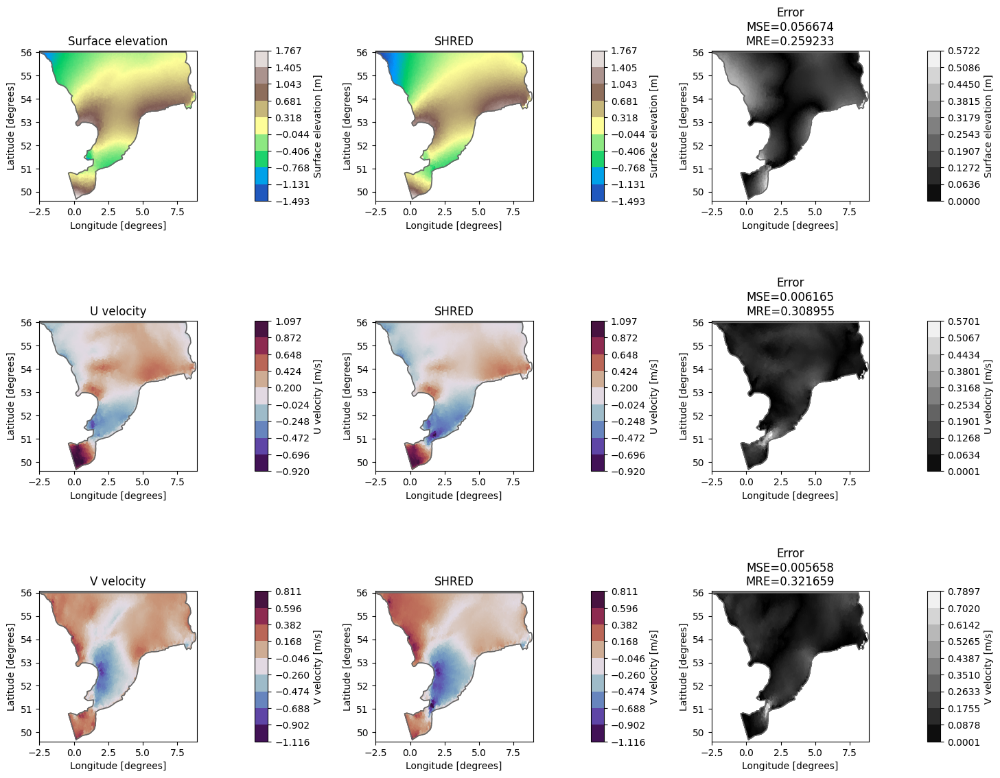

In [20]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="T_1_A_median_imputation")

del engine, test_reconstruction, ds_shred, ds_error, mshred

## Idea T.1.B: Mean imputer

In [21]:
# Data manager

lags = 24
manager = DataManager(lags = lags, train_size = 0.8, val_size = 0.1, test_size = 0.1)

# add data to manager
manager.add_data(
    H, id = "Surface elevation" , compress = 12, 
    measurements = measurements, imputer="mean"
)
manager.add_data(U, id = "U velocity", compress = 40)
manager.add_data(V, id = "V velocity", compress = 68)

# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare(verbose = True)

# output shape is the compressed (SVD) dimension, not the raw spatial size
nn_input_shape = measurements.shape[1]
nn_output_shape = manager.data.shape[1]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)

Nuber of nan values in measurements after imputation: 0 

Residual energy of Surface elevation after keeping 12 modes: 0.1678 %
Residual energy of U velocity after keeping 40 modes: 0.1947 %
Residual energy of V velocity after keeping 68 modes: 0.1872 %

Datasets: ['Surface elevation', 'U velocity', 'V velocity']

Number of nan values in sensor measurements after masking: 0

Data shapes after preparation:
Train:	 torch.Size([28031, 24, 5]) -> torch.Size([28031, 120])
Val:	 torch.Size([3504, 24, 5]) -> torch.Size([3504, 120])
Test:	 torch.Size([3504, 24, 5]) -> torch.Size([3504, 120])

Input shape for the model: 5
Output shape for the model: 120


Starting training...


Training: 100%|██████████| 200/200 [27:30<00:00,  8.25s/it, Train Loss=0.0044, Val Loss=0.0046, Patience=2, Best Val Loss=0.0046, LR=0.00e+00] 

Training completed with best validation loss: 0.0046


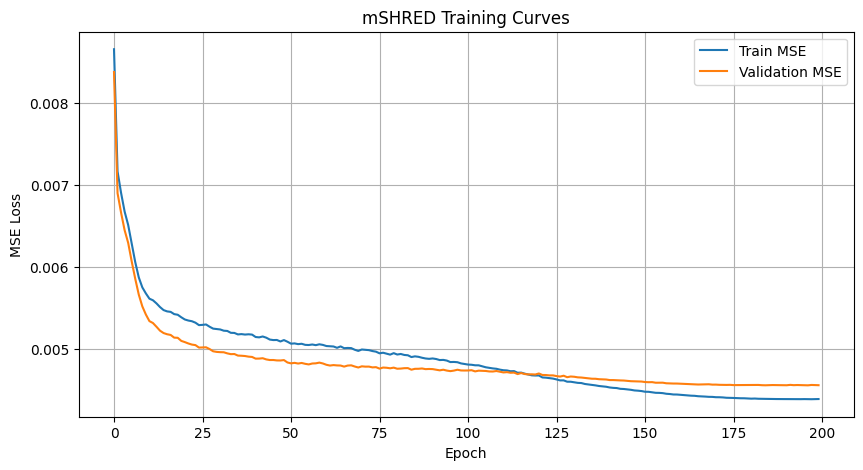

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + MLP,(T.0) only available sensors,0.004597,0.004661,0.011176,0.134996,0.134242,0.207774
1,(mSHRED) LSTM + CNN,(S.0) only available sensors,0.004379,0.004537,0.010846,0.131545,0.132755,0.204939
2,(mSHRED): TR + MLP,(T.1.A) median imputation for missing sensors,0.004416,0.004570,0.010951,0.132860,0.133064,0.206131
3,(mSHRED): TR + MLP,(T.1.B) mean imputation for missing sensors,0.004394,0.004564,0.010968,0.132458,0.132866,0.206169


In [22]:

# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer",
    encoder_depth=2,
    input_size=nn_input_shape,
    n_heads=4,
    dim_feedforward=64,
    hidden_size=32,
    input_length=lags,

    # Decoder
    decoder="mlp",
    decoder_hidden_sizes=[64],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
    double_channels=False,
)

mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=200,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=200,
    patience=60,
    verbose=True,
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors, label='Train MSE')
plt.plot(valid_errors, label='Validation MSE')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED Training Curves')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse, train_mre = evaluate(mshred, train_dataset)
val_mse, val_mre = evaluate(mshred, val_dataset)
test_mse, test_mre = evaluate(mshred, test_dataset)
test_error = {
    "model": f"(mSHRED): TR + MLP",
    "type" : "(T.1.B) mean imputation for missing sensors",
    "train-mse": float(train_mse),
    "val-mse": float(val_mse),
    "test-mse": float(test_mse),
    "train-mre": float(train_mre),
    "val-mre": float(val_mre),
    "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_T_1_B_mean_imputation.png


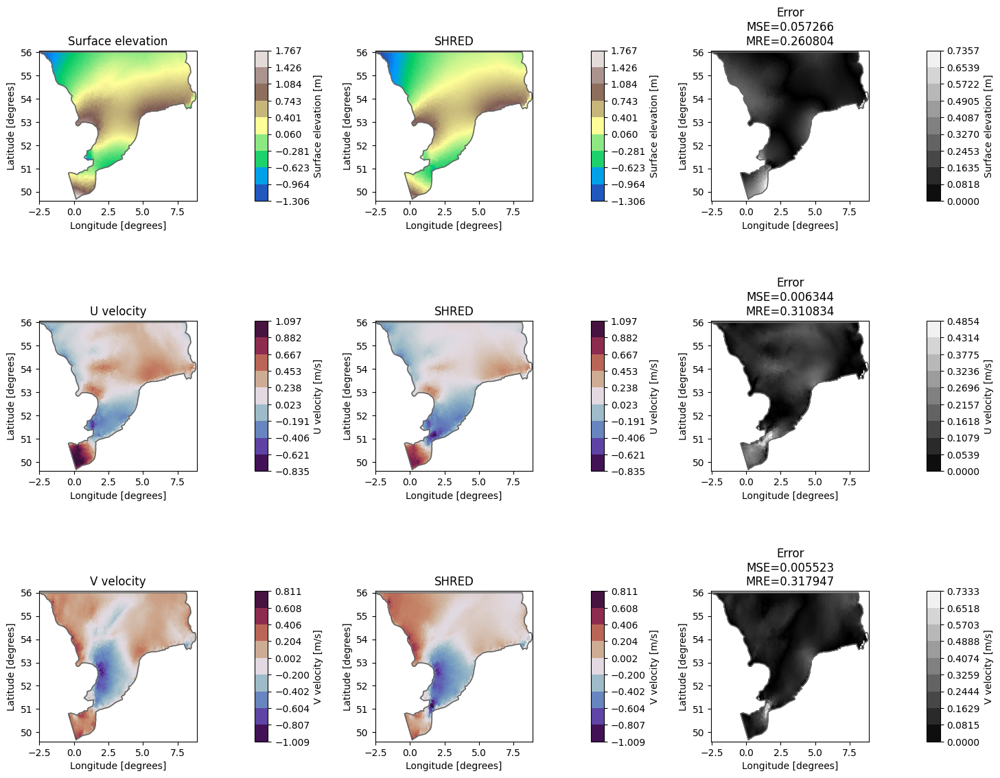

In [23]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="T_1_B_mean_imputation")

del engine, test_reconstruction, ds_shred, ds_error, mshred

## Idea T.1.C: Last value imputer

In [24]:

# Data manager

lags = 24
manager = DataManager(lags = lags, train_size = 0.8, val_size = 0.1, test_size = 0.1)

# add data to manager
manager.add_data(
    H, id = "Surface elevation" , compress = 12, 
    measurements = measurements, imputer="last_value"
 )
manager.add_data(U, id = "U velocity", compress = 40)
manager.add_data(V, id = "V velocity", compress = 68)

# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare(verbose = True)

# output shape is the compressed (SVD) dimension, not the raw spatial size
nn_input_shape = measurements.shape[1]
nn_output_shape = manager.data.shape[1]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)


Nuber of nan values in measurements after imputation: 0 

Residual energy of Surface elevation after keeping 12 modes: 0.1678 %
Residual energy of U velocity after keeping 40 modes: 0.1947 %
Residual energy of V velocity after keeping 68 modes: 0.1872 %

Datasets: ['Surface elevation', 'U velocity', 'V velocity']

Number of nan values in sensor measurements after masking: 0

Data shapes after preparation:
Train:	 torch.Size([28031, 24, 5]) -> torch.Size([28031, 120])
Val:	 torch.Size([3504, 24, 5]) -> torch.Size([3504, 120])
Test:	 torch.Size([3504, 24, 5]) -> torch.Size([3504, 120])

Input shape for the model: 5
Output shape for the model: 120


Starting training...


Training: 100%|██████████| 200/200 [26:22<00:00,  7.91s/it, Train Loss=0.0044, Val Loss=0.0046, Patience=32, Best Val Loss=0.0046, LR=0.00e+00]

Training completed with best validation loss: 0.0046


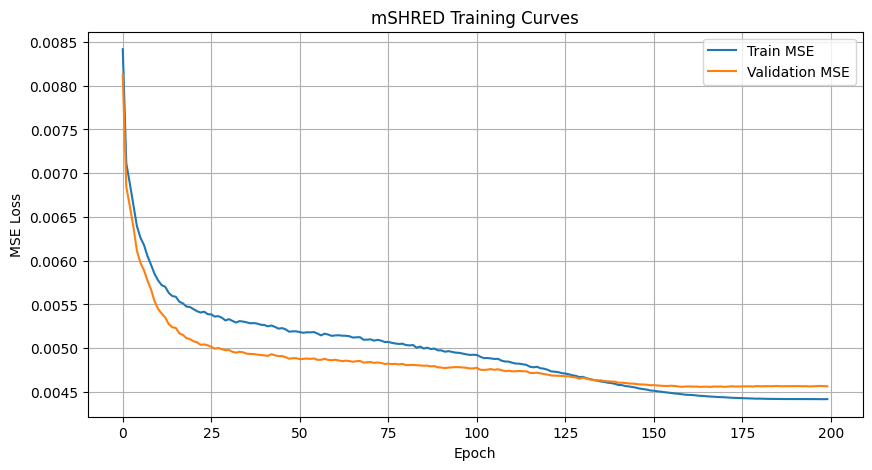

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + MLP,(T.0) only available sensors,0.004597,0.004661,0.011176,0.134996,0.134242,0.207774
1,(mSHRED) LSTM + CNN,(S.0) only available sensors,0.004379,0.004537,0.010846,0.131545,0.132755,0.204939
2,(mSHRED): TR + MLP,(T.1.A) median imputation for missing sensors,0.004416,0.004570,0.010951,0.132860,0.133064,0.206131
3,(mSHRED): TR + MLP,(T.1.B) mean imputation for missing sensors,0.004394,0.004564,0.010968,0.132458,0.132866,0.206169
4,(mSHRED): TR + MLP,(T.1.C) last value imputation for missing sensors,0.004419,0.004564,0.010986,0.132563,0.132852,0.206198


In [25]:

# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer",
    encoder_depth=2,
    input_size=nn_input_shape,
    n_heads=4,
    dim_feedforward=64,
    hidden_size=32,
    input_length=lags,

    # Decoder
    decoder="mlp",
    decoder_hidden_sizes=[64],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
    double_channels=False,
)

mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=200,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=200,
    patience=60,
    verbose=True,
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors, label='Train MSE')
plt.plot(valid_errors, label='Validation MSE')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED Training Curves')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse, train_mre = evaluate(mshred, train_dataset)
val_mse, val_mre = evaluate(mshred, val_dataset)
test_mse, test_mre = evaluate(mshred, test_dataset)
test_error = {
    "model": f"(mSHRED): TR + MLP",
    "type" : "(T.1.C) last value imputation for missing sensors",
    "train-mse": float(train_mse),
    "val-mse": float(val_mse),
    "test-mse": float(test_mse),
    "train-mre": float(train_mre),
    "val-mre": float(val_mre),
    "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_T_1_C_last_value_imputation.png


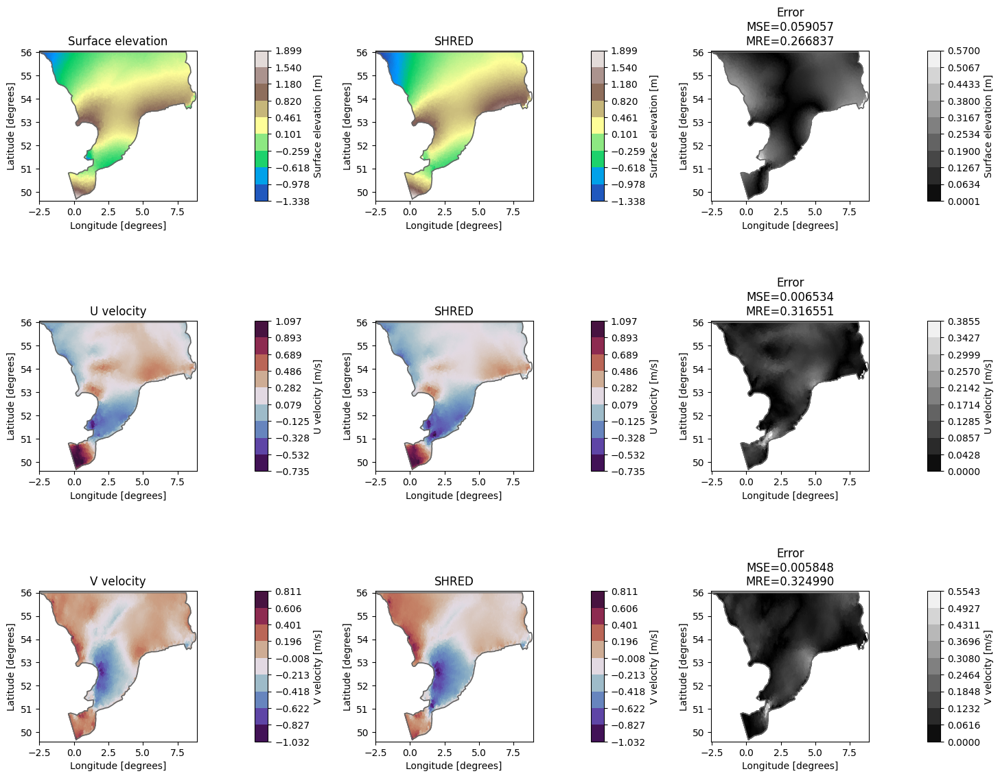

In [26]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="T_1_C_last_value_imputation")

del engine, test_reconstruction, ds_shred, ds_error, mshred

## Idea 2.A: GRUD

In [27]:

# Data manager
lags = 24
manager = DataManager(lags = lags, train_size = 0.8, val_size = 0.1, test_size = 0.1)

# add data to manager
manager.add_data(
    H, id = "Surface elevation" , compress = 12, 
    measurements = measurements
)
manager.add_data(U, id = "U velocity", compress = 40)
manager.add_data(V, id = "V velocity", compress = 68)

# prepare datasets
train_dataset, val_dataset, test_dataset, X_mean = manager.prepare(verbose = True, masking_type="grud")

# output shape is the compressed (SVD) dimension, not the raw spatial size
nn_input_shape = measurements.shape[1]
nn_output_shape = manager.data.shape[1]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)


Nuber of nan values in measurements after imputation: 45724 

Residual energy of Surface elevation after keeping 12 modes: 0.1678 %
Residual energy of U velocity after keeping 40 modes: 0.1947 %
Residual energy of V velocity after keeping 68 modes: 0.1872 %

Datasets: ['Surface elevation', 'U velocity', 'V velocity']

Number of nan values in sensor measurements after masking: 0

Data shapes after preparation:
Train:	 torch.Size([28031, 4, 24, 5]) -> torch.Size([28031, 120])
Val:	 torch.Size([3504, 4, 24, 5]) -> torch.Size([3504, 120])
Test:	 torch.Size([3504, 4, 24, 5]) -> torch.Size([3504, 120])

Input shape for the model: 5
Output shape for the model: 120


Starting training...


Training: 100%|██████████| 200/200 [23:36<00:00,  7.08s/it, Train Loss=0.0044, Val Loss=0.0046, Patience=12, Best Val Loss=0.0046, LR=0.00e+00]

Training completed with best validation loss: 0.0046


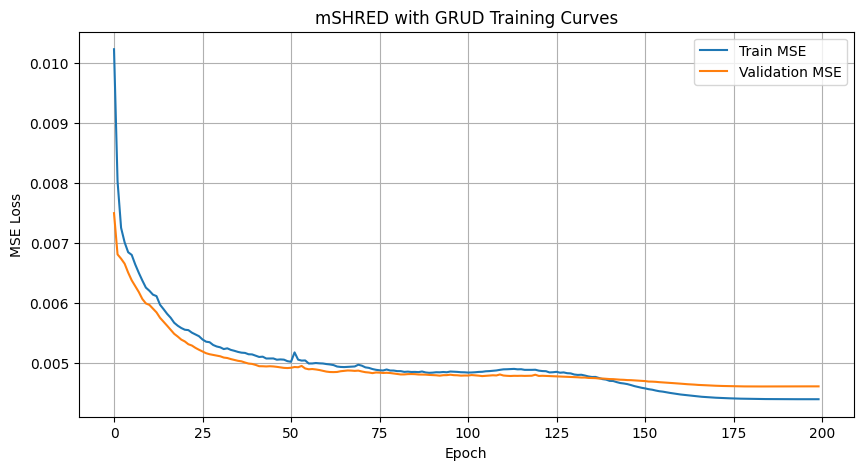

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + MLP,(T.0) only available sensors,0.004597,0.004661,0.011176,0.134996,0.134242,0.207774
1,(mSHRED) LSTM + CNN,(S.0) only available sensors,0.004379,0.004537,0.010846,0.131545,0.132755,0.204939
2,(mSHRED): TR + MLP,(T.1.A) median imputation for missing sensors,0.004416,0.004570,0.010951,0.132860,0.133064,0.206131
3,(mSHRED): TR + MLP,(T.1.B) mean imputation for missing sensors,0.004394,0.004564,0.010968,0.132458,0.132866,0.206169
4,(mSHRED): TR + MLP,(T.1.C) last value imputation for missing sensors,0.004419,0.004564,0.010986,0.132563,0.132852,0.206198
5,(mSHRED): GRUD + CNN,(2.A) GRUD masking,0.004400,0.004614,0.010857,0.132940,0.134315,0.204946


In [28]:
# GRUD TRAINING
model_args = dict(
    # Encoder
    encoder="grud",
    input_size=nn_input_shape,
    hidden_size=32,
    X_mean=X_mean,

    # Decoder
    decoder="mlp",
    decoder_hidden_sizes=[64],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
)

mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=200,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=200,
    patience=60,
    verbose=True,
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors, label='Train MSE')
plt.plot(valid_errors, label='Validation MSE')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED with GRUD Training Curves')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse, train_mre = evaluate(mshred, train_dataset)
val_mse, val_mre = evaluate(mshred, val_dataset)
test_mse, test_mre = evaluate(mshred, test_dataset)
test_error = {
    "model": f"(mSHRED): GRUD + CNN",
    "type" : "(2.A) GRUD masking",
    "train-mse": float(train_mse),
    "val-mse": float(val_mse),
    "test-mse": float(test_mse),
    "train-mre": float(train_mre),
    "val-mre": float(val_mre),
    "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_2_A_GRUD_masking.png


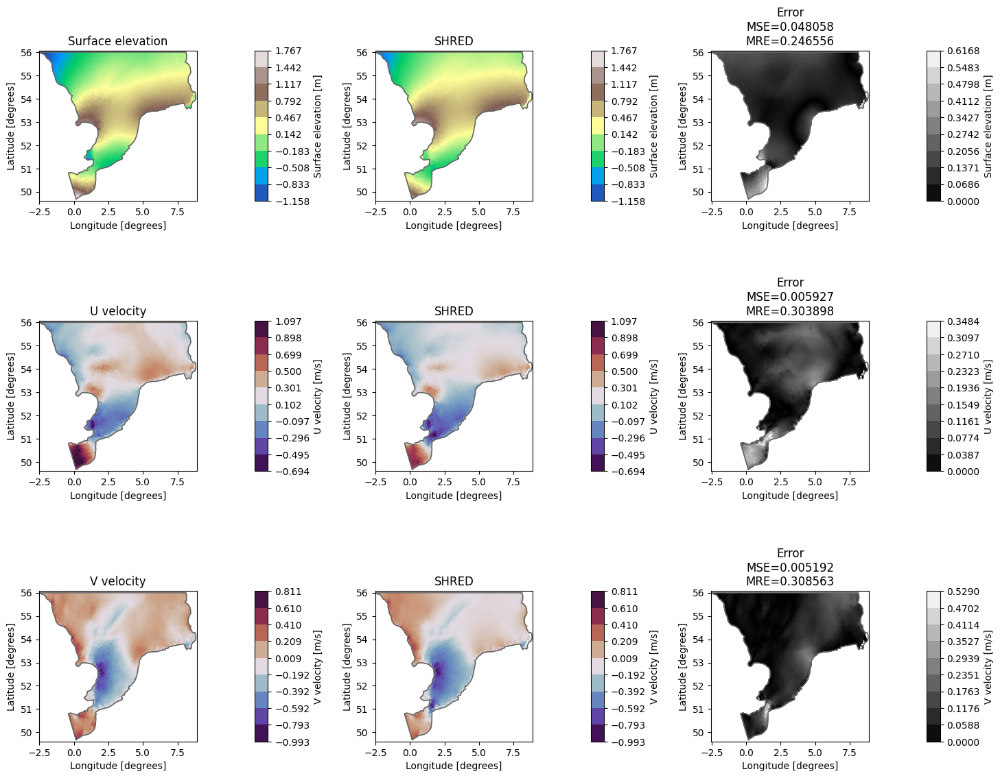

In [29]:

# mSHRED RECONSTRUCTION

engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_grud, ds_error_grud = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="2_A_GRUD_masking")

del engine, test_reconstruction, ds_grud, ds_error_grud, mshred


## Idea 2.B: Attn AGRUD


In [31]:
# GRUD TRAINING
model_args = dict(
    # Encoder
    encoder="att_grud",
    input_size=nn_input_shape,
    hidden_size=32,
    X_mean=X_mean,

    # Decoder
    decoder="mlp",
    decoder_hidden_sizes=[64],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
)

mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=200,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=200,
    patience=60,
    verbose=True,
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors, label='Train MSE')
plt.plot(valid_errors, label='Validation MSE')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED with GRUD Training Curves')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse, train_mre = evaluate(mshred, train_dataset)
val_mse, val_mre = evaluate(mshred, val_dataset)
test_mse, test_mre = evaluate(mshred, test_dataset)
test_error = {
    "model": f"(mSHRED): attnGRUD + CNN",
    "type" : "(2.B) GRUD masking",
    "train-mse": float(train_mse),
    "val-mse": float(val_mse),
    "test-mse": float(test_mse),
    "train-mre": float(train_mre),
    "val-mre": float(val_mre),
    "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + MLP,(T.0) only available sensors,0.004597,0.004661,0.011176,0.134996,0.134242,0.207774
1,(mSHRED) LSTM + CNN,(S.0) only available sensors,0.004379,0.004537,0.010846,0.131545,0.132755,0.204939
2,(mSHRED): TR + MLP,(T.1.A) median imputation for missing sensors,0.004416,0.004570,0.010951,0.132860,0.133064,0.206131
3,(mSHRED): TR + MLP,(T.1.B) mean imputation for missing sensors,0.004394,0.004564,0.010968,0.132458,0.132866,0.206169
4,(mSHRED): TR + MLP,(T.1.C) last value imputation for missing sensors,0.004419,0.004564,0.010986,0.132563,0.132852,0.206198
5,(mSHRED): GRUD + CNN,(2.A) GRUD masking,0.004400,0.004614,0.010857,0.132940,0.134315,0.204946
6,(mSHRED): attnGRUD + CNN,(2.B) GRUD masking,0.004722,0.004766,0.011245,0.138796,0.137198,0.208968


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_2_B_attnGRUD_masking.png


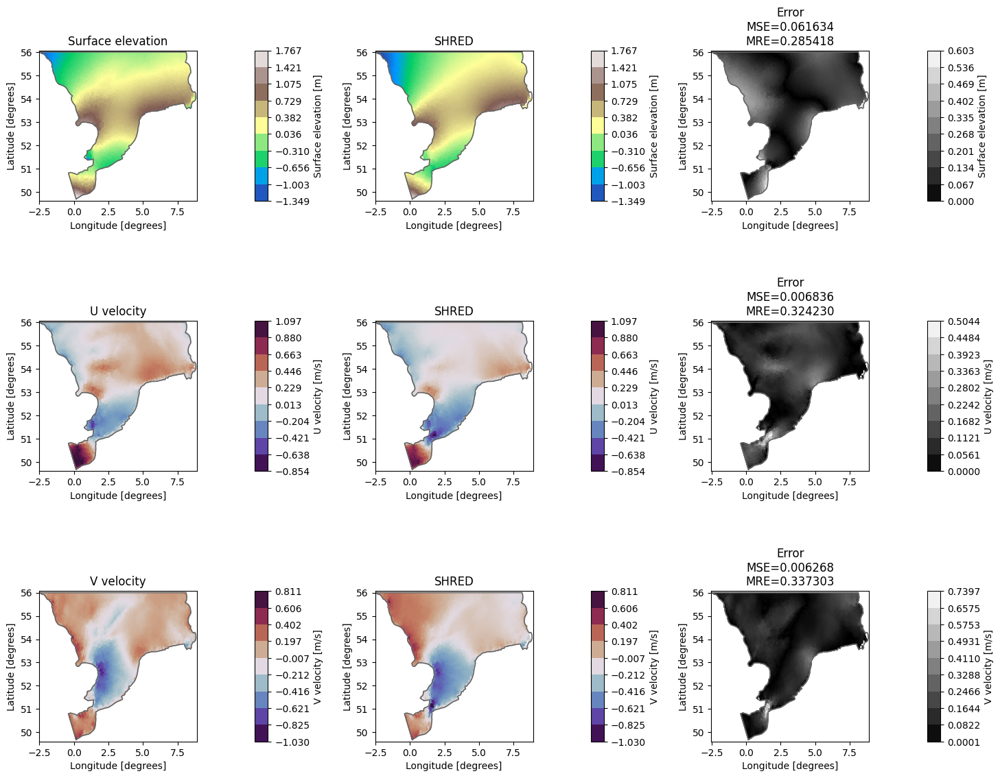

In [32]:

# mSHRED RECONSTRUCTION

engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_grud, ds_error_grud = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="2_B_attnGRUD_masking")

del engine, test_reconstruction, ds_grud, ds_error_grud, mshred, manager


## Masking

In [13]:

# Data manager

lags = 24
manager = DataManager(lags = lags, train_size = 0.8, val_size = 0.1, test_size = 0.1)

# add data to manager
manager.add_data(H, id = "Surface elevation" , compress = 12, measurements = measurements)
manager.add_data(U, id = "U velocity", compress = 40)
manager.add_data(V, id = "V velocity", compress = 68)

# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare(verbose = True, masking_type="mask_data")

# output shape is the compressed (SVD) dimension, not the raw spatial size
nn_input_shape = train_dataset.X.shape[-1]
nn_output_shape = train_dataset.Y.shape[-1]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)


Nuber of nan values in measurements after imputation: 45724 

Residual energy of Surface elevation after keeping 12 modes: 0.1678 %
Residual energy of U velocity after keeping 40 modes: 0.1947 %
Residual energy of V velocity after keeping 68 modes: 0.1872 %

Datasets: ['Surface elevation', 'U velocity', 'V velocity']

Number of nan values in sensor measurements after masking: 45724

Data shapes after preparation:
Train:	 torch.Size([28031, 24, 5]) -> torch.Size([28031, 120])
Val:	 torch.Size([3504, 24, 5]) -> torch.Size([3504, 120])
Test:	 torch.Size([3504, 24, 5]) -> torch.Size([3504, 120])

Input shape for the model: 5
Output shape for the model: 120


## Idea 3.0: TSHRED

Starting training...


Training: 100%|██████████| 200/200 [25:55<00:00,  7.78s/it, Train Loss=0.0044, Val Loss=0.0046, Patience=4, Best Val Loss=0.0046, LR=0.00e+00]

Training completed with best validation loss: 0.0046


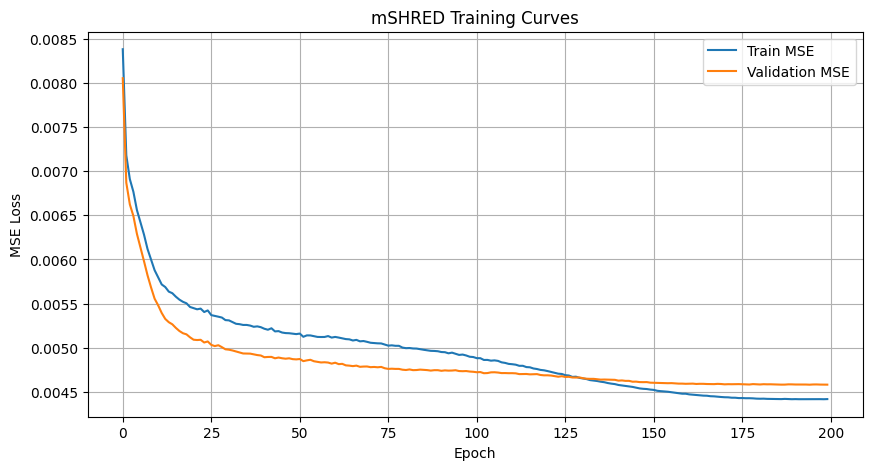

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + MLP,(3.0) TSHRED,0.004417,0.004587,0.011018,0.132274,0.133386,0.205826


In [14]:

# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer",
    encoder_depth=2,
    input_size=nn_input_shape,
    n_heads=4,
    dim_feedforward=64,
    hidden_size=32,
    input_length=lags,

    # Decoder
    decoder="mlp",
    decoder_hidden_sizes=[64],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
    double_channels=False
)

mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=200,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=200,
    patience=60,
    verbose=True,
    masking_type= "mask_data"
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors, label='Train MSE')
plt.plot(valid_errors, label='Validation MSE')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED Training Curves')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse, train_mre = evaluate(mshred, train_dataset,masking_type= "mask_data")
val_mse, val_mre = evaluate(mshred, val_dataset,masking_type= "mask_data")
test_mse, test_mre = evaluate(mshred, test_dataset,masking_type= "mask_data")
test_error = {
    "model": f"(mSHRED): TR + MLP",
    "type" : "(3.0) TSHRED",
    "train-mse": float(train_mse),
    "val-mse": float(val_mse),
    "test-mse": float(test_mse),
    "train-mre": float(train_mre),
    "val-mre": float(val_mre),
    "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_3_0_tshred.png


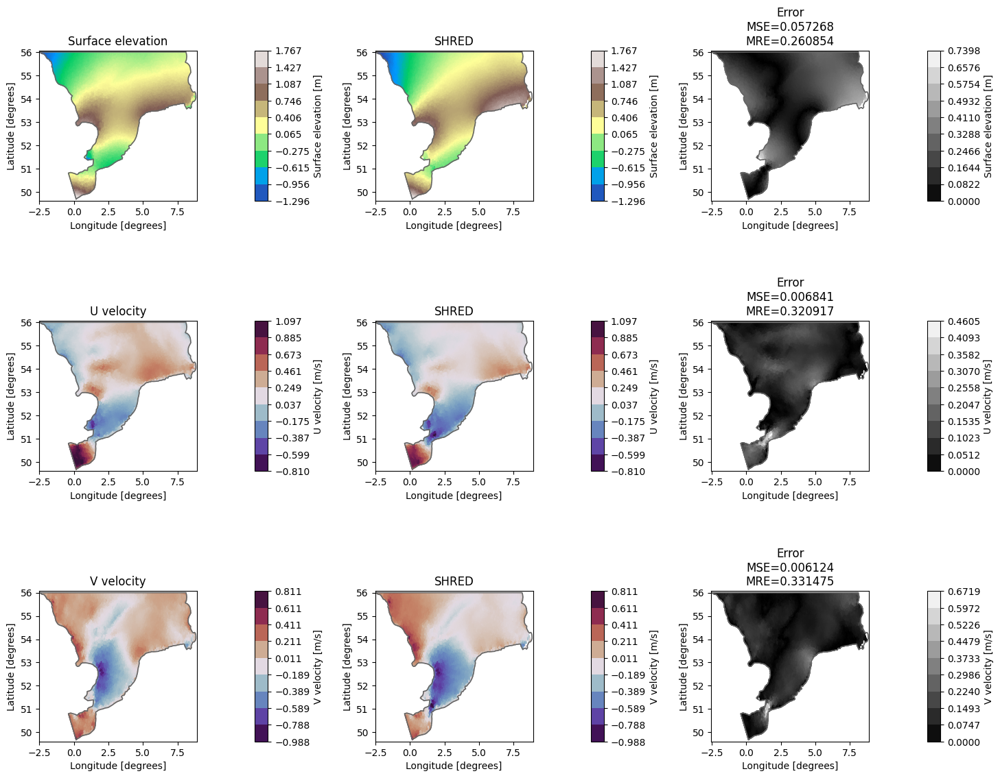

In [15]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="3_0_tshred")

del engine, test_reconstruction, ds_shred, ds_error, mshred

## Idea 3.A: Mask double channels

Starting training...


Training:   0%|          | 0/200 [00:00<?, ?it/s]

Training: 100%|██████████| 200/200 [26:13<00:00,  7.87s/it, Train Loss=0.0043, Val Loss=0.0046, Patience=3, Best Val Loss=0.0046, LR=0.00e+00]

Training completed with best validation loss: 0.0046


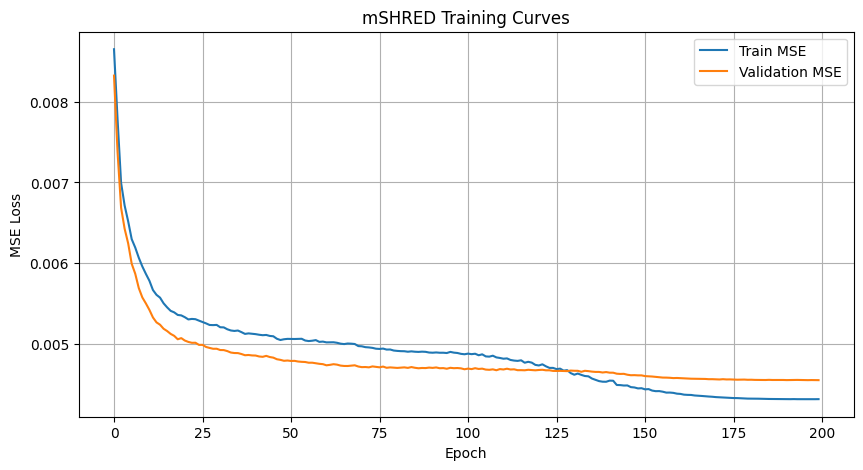

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + MLP,(3.0) TSHRED,0.004417,0.004587,0.011018,0.132274,0.133386,0.205826
1,(mSHRED): TR + MLP,(3.A) Mask double channels,0.004315,0.004553,0.010871,0.130966,0.132617,0.204816


In [16]:

# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer",
    encoder_depth=2,
    input_size=nn_input_shape,
    n_heads=4,
    dim_feedforward=64,
    hidden_size=32,
    input_length=lags,

    # Decoder
    decoder="mlp",
    decoder_hidden_sizes=[64],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
    double_channels=True,
)

mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=200,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=200,
    patience=60,
    verbose=True,
    masking_type= "mask_data"
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors, label='Train MSE')
plt.plot(valid_errors, label='Validation MSE')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED Training Curves')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse, train_mre = evaluate(mshred, train_dataset,masking_type= "mask_data")
val_mse, val_mre = evaluate(mshred, val_dataset,masking_type= "mask_data")
test_mse, test_mre = evaluate(mshred, test_dataset,masking_type= "mask_data")
test_error = {
    "model": f"(mSHRED): TR + MLP",
    "type" : "(3.A) Mask double channels",
    "train-mse": float(train_mse),
    "val-mse": float(val_mse),
    "test-mse": float(test_mse),
    "train-mre": float(train_mre),
    "val-mre": float(val_mre),
    "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_3_A_mask_double_channels.png


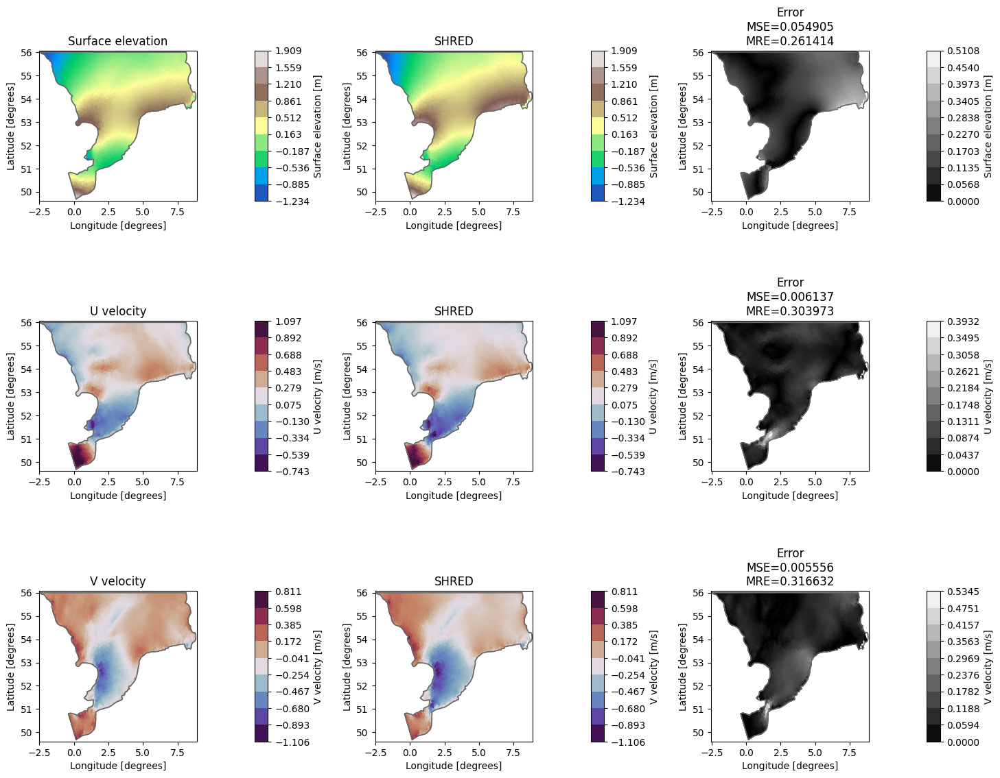

In [17]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="3_A_mask_double_channels")

del engine, test_reconstruction, ds_shred, ds_error, mshred

## Idea 3.B: Mask in the hidden space

Starting training...


Training: 100%|██████████| 200/200 [25:41<00:00,  7.71s/it, Train Loss=0.0044, Val Loss=0.0046, Patience=0, Best Val Loss=0.0046, LR=0.00e+00]

Training completed with best validation loss: 0.0046


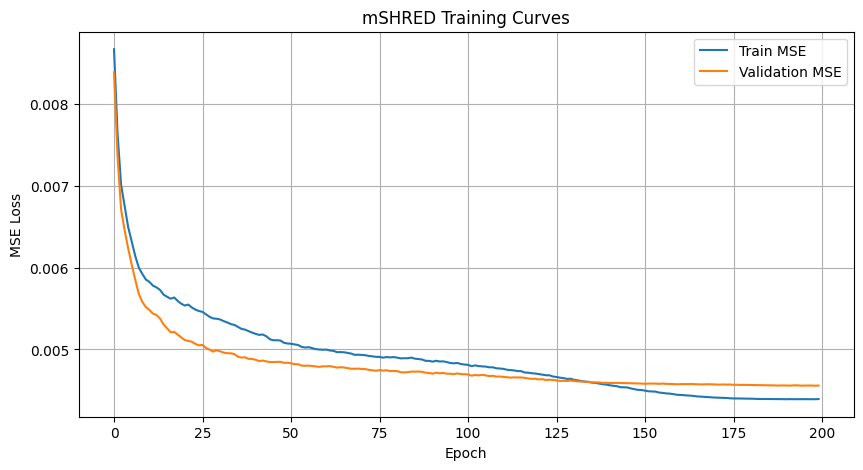

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + MLP,(3.0) TSHRED,0.004417,0.004587,0.011018,0.132274,0.133386,0.205826
1,(mSHRED): TR + MLP,(3.A) Mask double channels,0.004315,0.004553,0.010871,0.130966,0.132617,0.204816
2,(mSHRED): TR + MLP,(3.B) Mask the hidden state,0.004392,0.004560,0.011081,0.132065,0.132784,0.206771


In [18]:

# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer_hidden_mask",
    encoder_depth=2,
    input_size=nn_input_shape,
    n_heads=4,
    dim_feedforward=64,
    hidden_size=32,
    input_length=lags,

    # Decoder
    decoder="mlp",
    decoder_hidden_sizes=[64],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
)

mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=200,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=200,
    patience=60,
    verbose=True,
    masking_type="mask_data"
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors, label='Train MSE')
plt.plot(valid_errors, label='Validation MSE')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED Training Curves')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse, train_mre = evaluate(mshred, train_dataset, masking_type="mask_data")
val_mse, val_mre = evaluate(mshred, val_dataset, masking_type="mask_data")
test_mse, test_mre = evaluate(mshred, test_dataset, masking_type="mask_data")
test_error = {
    "model": f"(mSHRED): TR + MLP",
    "type" : "(3.B) Mask the hidden state",
    "train-mse": float(train_mse),
    "val-mse": float(val_mse),
    "test-mse": float(test_mse),
    "train-mre": float(train_mre),
    "val-mre": float(val_mre),
    "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_3_B_mask_hidden_state.png


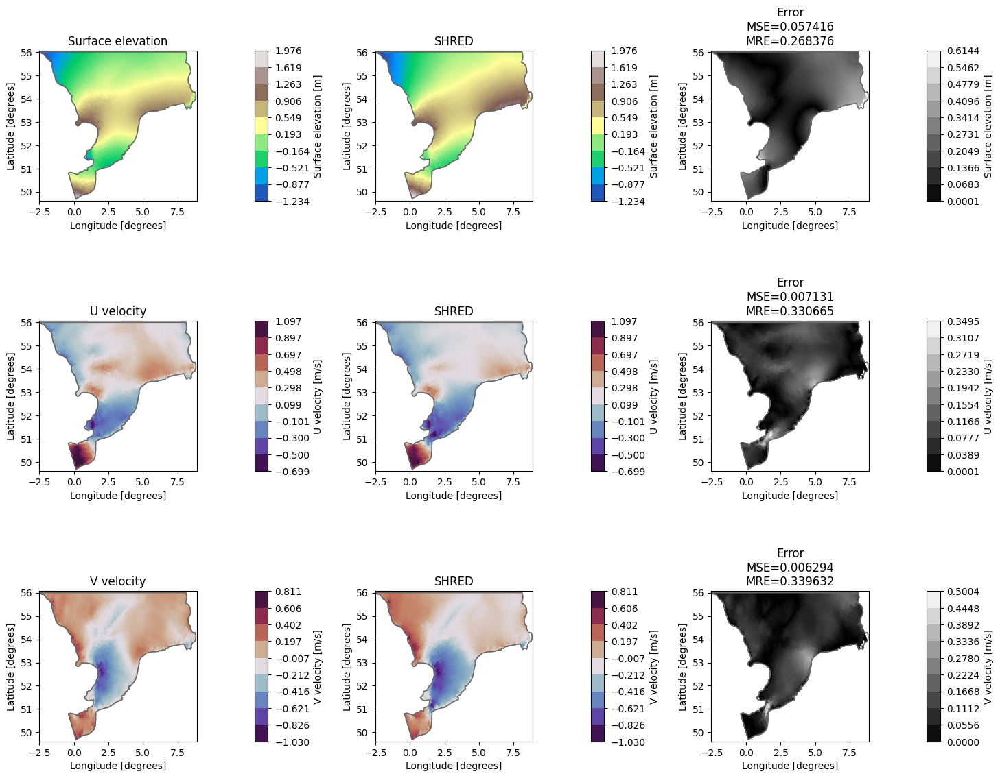

In [19]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="3_B_mask_hidden_state")

del engine, test_reconstruction, ds_shred, ds_error, mshred

## Idea 3.C: Mask in the attention block

Starting training...


Training: 100%|██████████| 200/200 [25:48<00:00,  7.74s/it, Train Loss=0.0044, Val Loss=0.0046, Patience=1, Best Val Loss=0.0046, LR=0.00e+00]

Training completed with best validation loss: 0.0046


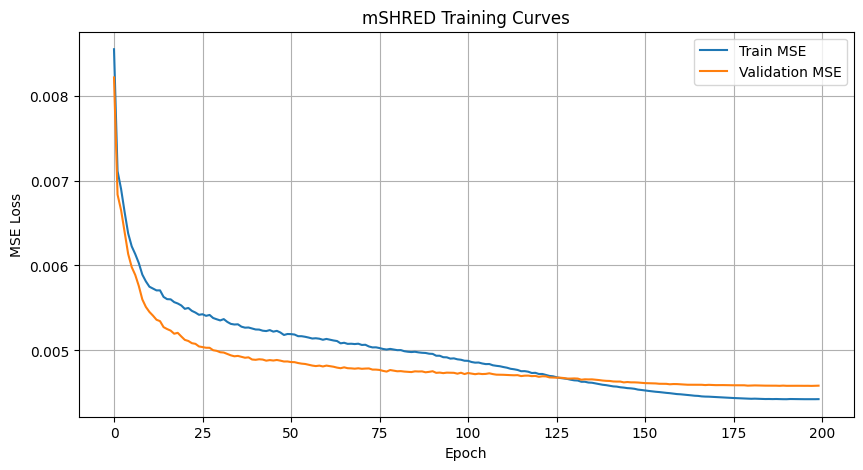

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + MLP,(3.0) TSHRED,0.004417,0.004587,0.011018,0.132274,0.133386,0.205826
1,(mSHRED): TR + MLP,(3.A) Mask double channels,0.004315,0.004553,0.010871,0.130966,0.132617,0.204816
2,(mSHRED): TR + MLP,(3.B) Mask the hidden state,0.004392,0.004560,0.011081,0.132065,0.132784,0.206771
3,(mSHRED): TR + MLP,(3.C) Mask in the attention block,0.004426,0.004586,0.011050,0.132404,0.133236,0.206031


In [20]:

# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer_attn_mask",
    encoder_depth=2,
    input_size=nn_input_shape,
    n_heads=4,
    dim_feedforward=64,
    hidden_size=32,
    input_length=lags,

    # Decoder
    decoder="mlp",
    decoder_hidden_sizes=[64],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
    double_channels=False,
)

mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=200,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=200,
    patience=60,
    verbose=True,
    masking_type="mask_data"
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors, label='Train MSE')
plt.plot(valid_errors, label='Validation MSE')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED Training Curves')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse, train_mre = evaluate(mshred, train_dataset, masking_type="mask_data")
val_mse, val_mre = evaluate(mshred, val_dataset, masking_type="mask_data")
test_mse, test_mre = evaluate(mshred, test_dataset, masking_type="mask_data")
test_error = {
    "model": f"(mSHRED): TR + MLP",
    "type" : "(3.C) Mask in the attention block",
    "train-mse": float(train_mse),
    "val-mse": float(val_mse),
    "test-mse": float(test_mse),
    "train-mre": float(train_mre),
    "val-mre": float(val_mre),
    "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_3_C_mask_attention_block.png


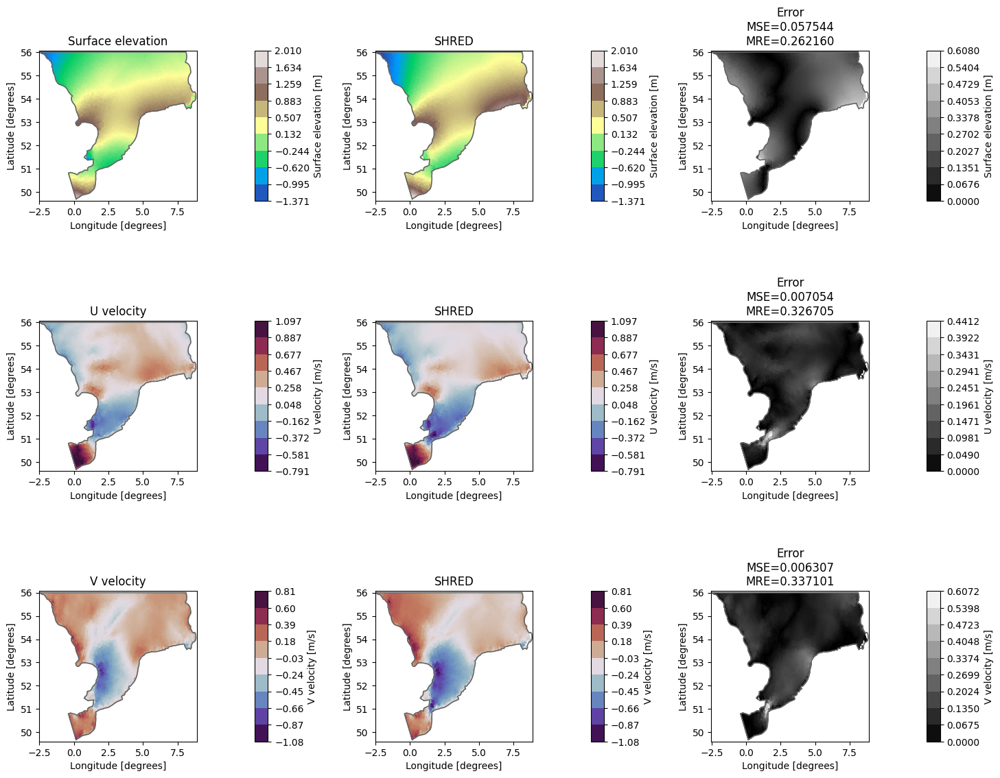

In [21]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="3_C_mask_attention_block")

del engine, test_reconstruction, ds_shred, ds_error, mshred

## Idea 3.D: Attention mask + double channels

Starting training...


Training: 100%|██████████| 200/200 [30:39<00:00,  9.20s/it, Train Loss=0.0043, Val Loss=0.0045, Patience=3, Best Val Loss=0.0045, LR=0.00e+00]

Training completed with best validation loss: 0.0045


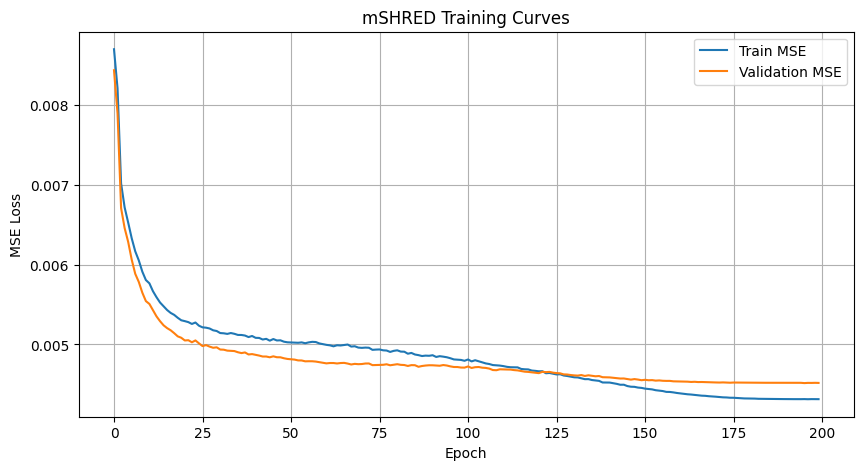

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + MLP,(3.0) TSHRED,0.004417,0.004587,0.011018,0.132274,0.133386,0.205826
1,(mSHRED): TR + MLP,(3.A) Mask double channels,0.004315,0.004553,0.010871,0.130966,0.132617,0.204816
2,(mSHRED): TR + MLP,(3.B) Mask the hidden state,0.004392,0.004560,0.011081,0.132065,0.132784,0.206771
3,(mSHRED): TR + MLP,(3.C) Mask in the attention block,0.004426,0.004586,0.011050,0.132404,0.133236,0.206031
4,(mSHRED): TR + MLP,(3.D) Double masking,0.004315,0.004517,0.010918,0.130881,0.132112,0.205263


In [22]:

# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer_attn_mask",
    encoder_depth=2,
    input_size=nn_input_shape,
    n_heads=4,
    dim_feedforward=64,
    hidden_size=32,
    input_length=lags,

    # Decoder
    decoder="mlp",
    decoder_hidden_sizes=[64],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
    double_channels=True,
)

mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=200,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=200,
    patience=60,
    verbose=True,
    masking_type="mask_data"
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors, label='Train MSE')
plt.plot(valid_errors, label='Validation MSE')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED Training Curves')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse, train_mre = evaluate(mshred, train_dataset, masking_type="mask_data")
val_mse, val_mre = evaluate(mshred, val_dataset, masking_type="mask_data")
test_mse, test_mre = evaluate(mshred, test_dataset, masking_type="mask_data")
test_error = {
    "model": f"(mSHRED): TR + MLP",
    "type" : "(3.D) Double masking",
    "train-mse": float(train_mse),
    "val-mse": float(val_mse),
    "test-mse": float(test_mse),
    "train-mre": float(train_mre),
    "val-mre": float(val_mre),
    "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_3_D_double_masking.png


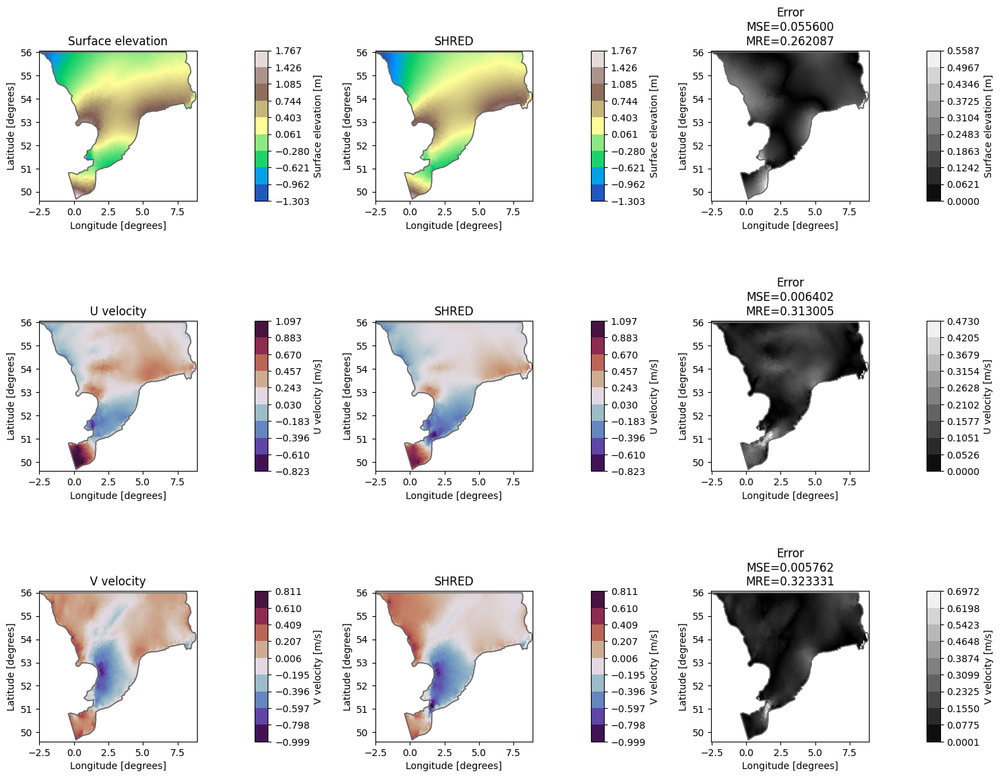

In [23]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="3_D_double_masking")

del engine, test_reconstruction, ds_shred, ds_error, mshred

## Idea 3.E: learn the mask in the softmax


Starting training...


Training: 100%|██████████| 200/200 [32:14<00:00,  9.67s/it, Train Loss=0.0043, Val Loss=0.0046, Patience=13, Best Val Loss=0.0046, LR=0.00e+00]

Training completed with best validation loss: 0.0046


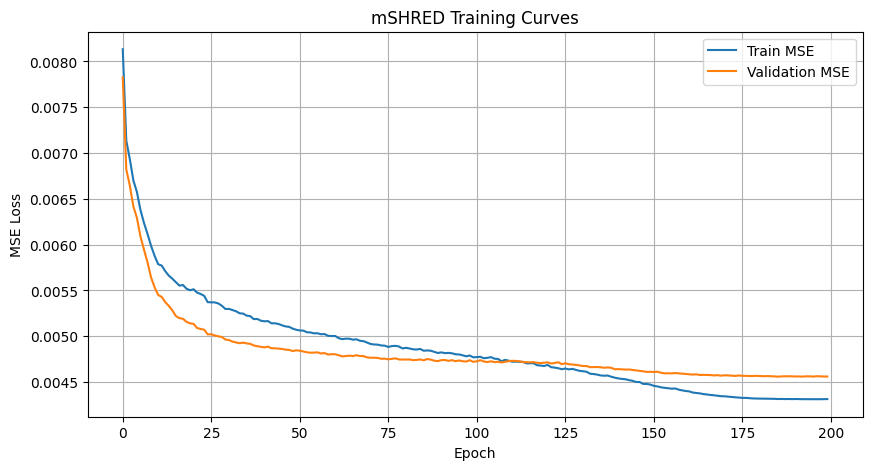

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + MLP,(3.0) TSHRED,0.004417,0.004587,0.011018,0.132274,0.133386,0.205826
1,(mSHRED): TR + MLP,(3.A) Mask double channels,0.004315,0.004553,0.010871,0.130966,0.132617,0.204816
2,(mSHRED): TR + MLP,(3.B) Mask the hidden state,0.004392,0.004560,0.011081,0.132065,0.132784,0.206771
3,(mSHRED): TR + MLP,(3.C) Mask in the attention block,0.004426,0.004586,0.011050,0.132404,0.133236,0.206031
4,(mSHRED): TR + MLP,(3.D) Double masking,0.004315,0.004517,0.010918,0.130881,0.132112,0.205263
5,(mSHRED): TR + MLP,(3.E) Transformer Learned mask,0.004314,0.004561,0.010837,0.131055,0.133162,0.204545


In [24]:

# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer_learned_mask",
    encoder_depth=2,
    input_size=nn_input_shape,
    n_heads=4,
    dim_feedforward=64,
    hidden_size=32,
    input_length=lags,

    # Decoder
    decoder="mlp",
    decoder_hidden_sizes=[64],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
)

mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=200,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=200,
    patience=60,
    verbose=True,
    masking_type="mask_data"
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors, label='Train MSE')
plt.plot(valid_errors, label='Validation MSE')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED Training Curves')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse, train_mre = evaluate(mshred, train_dataset, masking_type="mask_data")
val_mse, val_mre = evaluate(mshred, val_dataset, masking_type="mask_data")
test_mse, test_mre = evaluate(mshred, test_dataset, masking_type="mask_data")
test_error = {
    "model": f"(mSHRED): TR + MLP",
    "type" : "(3.E) Transformer Learned mask",
    "train-mse": float(train_mse),
    "val-mse": float(val_mse),
    "test-mse": float(test_mse),
    "train-mre": float(train_mre),
    "val-mre": float(val_mre),
    "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_3_D_learn_mask_softmax.png


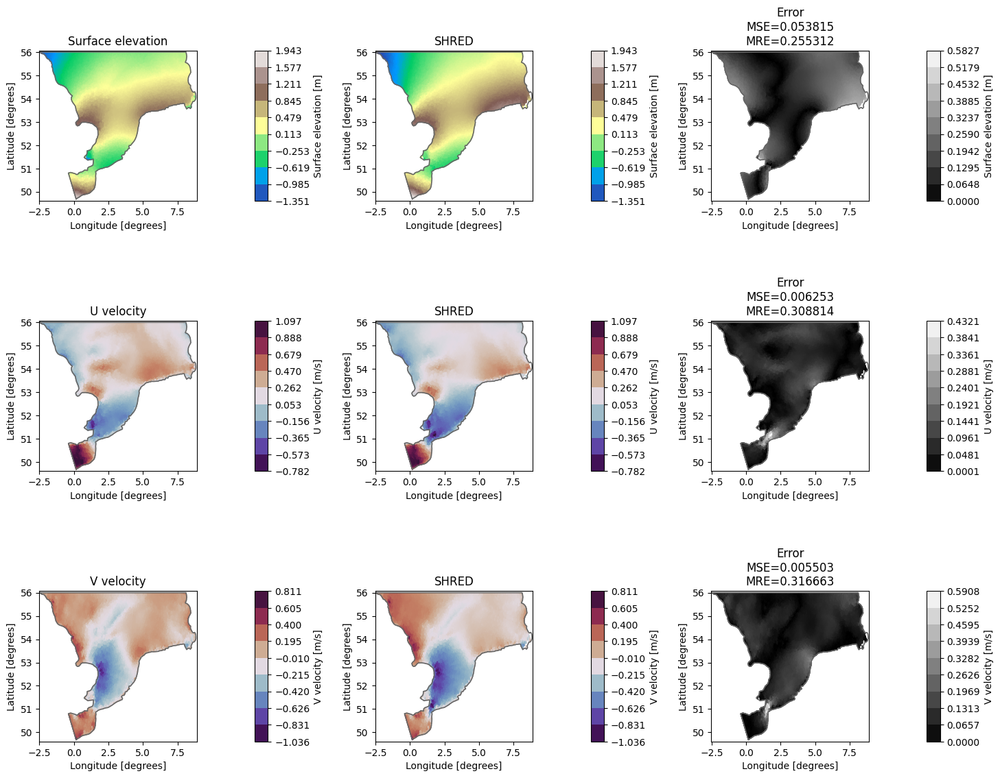

In [25]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="3_D_learn_mask_softmax")

del engine, test_reconstruction, ds_shred, ds_error, mshred

## Idea 3.F: Learned mask + double channels


Starting training...


Training: 100%|██████████| 200/200 [32:13<00:00,  9.67s/it, Train Loss=0.0043, Val Loss=0.0045, Patience=1, Best Val Loss=0.0045, LR=0.00e+00] 

Training completed with best validation loss: 0.0045


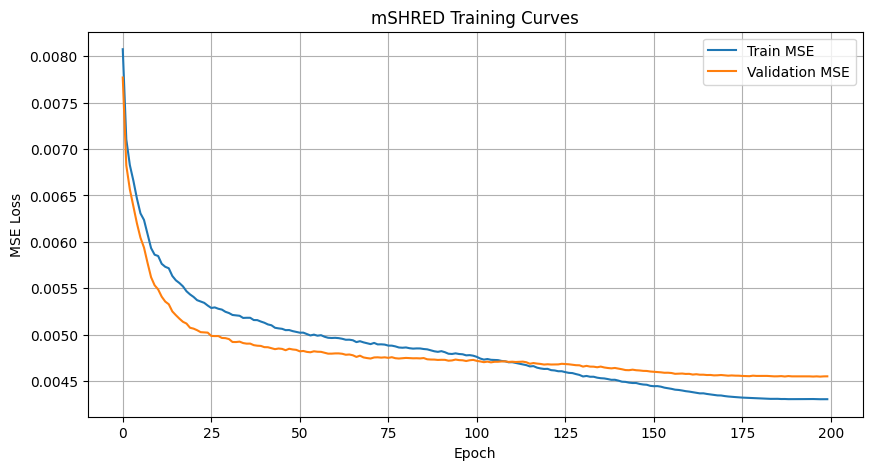

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + MLP,(3.0) TSHRED,0.004417,0.004587,0.011018,0.132274,0.133386,0.205826
1,(mSHRED): TR + MLP,(3.A) Mask double channels,0.004315,0.004553,0.010871,0.130966,0.132617,0.204816
2,(mSHRED): TR + MLP,(3.B) Mask the hidden state,0.004392,0.004560,0.011081,0.132065,0.132784,0.206771
3,(mSHRED): TR + MLP,(3.C) Mask in the attention block,0.004426,0.004586,0.011050,0.132404,0.133236,0.206031
4,(mSHRED): TR + MLP,(3.D) Double masking,0.004315,0.004517,0.010918,0.130881,0.132112,0.205263
5,(mSHRED): TR + MLP,(3.E) Transformer Learned mask,0.004314,0.004561,0.010837,0.131055,0.133162,0.204545
6,(mSHRED): TR + MLP,(3.F) Transformer Learned mask + double channels,0.004304,0.004549,0.010807,0.130640,0.132873,0.204134


In [26]:

# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer_learned_mask",
    encoder_depth=2,
    input_size=nn_input_shape,
    n_heads=4,
    dim_feedforward=64,
    hidden_size=32,
    input_length=lags,

    # Decoder
    decoder="mlp",
    decoder_hidden_sizes=[64],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
    double_channels=True,
)

mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=200,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=200,
    patience=60,
    verbose=True,
    masking_type="mask_data"
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors, label='Train MSE')
plt.plot(valid_errors, label='Validation MSE')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED Training Curves')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse, train_mre = evaluate(mshred, train_dataset, masking_type="mask_data")
val_mse, val_mre = evaluate(mshred, val_dataset, masking_type="mask_data")
test_mse, test_mre = evaluate(mshred, test_dataset, masking_type="mask_data")
test_error = {
    "model": f"(mSHRED): TR + MLP",
    "type" : "(3.F) Transformer Learned mask + double channels",
    "train-mse": float(train_mse),
    "val-mse": float(val_mse),
    "test-mse": float(test_mse),
    "train-mre": float(train_mre),
    "val-mre": float(val_mre),
    "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_3_F_learn_mask_double_channels.png


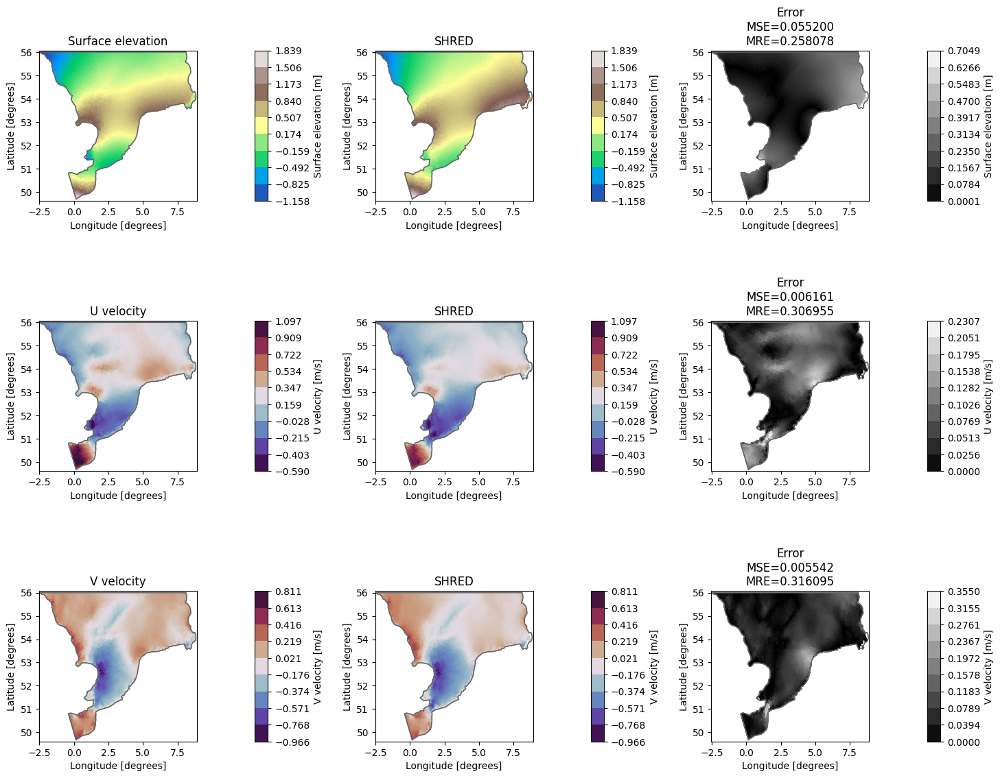

In [27]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="3_F_learn_mask_double_channels")

del engine, test_reconstruction, ds_shred, ds_error, mshred

## Results

In [28]:
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + MLP,(3.0) TSHRED,0.004417,0.004587,0.011018,0.132274,0.133386,0.205826
1,(mSHRED): TR + MLP,(3.A) Mask double channels,0.004315,0.004553,0.010871,0.130966,0.132617,0.204816
2,(mSHRED): TR + MLP,(3.B) Mask the hidden state,0.004392,0.004560,0.011081,0.132065,0.132784,0.206771
3,(mSHRED): TR + MLP,(3.C) Mask in the attention block,0.004426,0.004586,0.011050,0.132404,0.133236,0.206031
4,(mSHRED): TR + MLP,(3.D) Double masking,0.004315,0.004517,0.010918,0.130881,0.132112,0.205263
5,(mSHRED): TR + MLP,(3.E) Transformer Learned mask,0.004314,0.004561,0.010837,0.131055,0.133162,0.204545
6,(mSHRED): TR + MLP,(3.F) Transformer Learned mask + double channels,0.004304,0.004549,0.010807,0.130640,0.132873,0.204134


In [29]:
# order dataframe by test-mse
dataframe_errors = dataframe_errors.sort_values(by="test-mse")
display(dataframe_errors)

# order dataframe by test-mre
dataframe_errors = dataframe_errors.sort_values(by="test-mre")
display(dataframe_errors)

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
6,(mSHRED): TR + MLP,(3.F) Transformer Learned mask + double channels,0.004304,0.004549,0.010807,0.130640,0.132873,0.204134
5,(mSHRED): TR + MLP,(3.E) Transformer Learned mask,0.004314,0.004561,0.010837,0.131055,0.133162,0.204545
1,(mSHRED): TR + MLP,(3.A) Mask double channels,0.004315,0.004553,0.010871,0.130966,0.132617,0.204816
4,(mSHRED): TR + MLP,(3.D) Double masking,0.004315,0.004517,0.010918,0.130881,0.132112,0.205263
0,(mSHRED): TR + MLP,(3.0) TSHRED,0.004417,0.004587,0.011018,0.132274,0.133386,0.205826
3,(mSHRED): TR + MLP,(3.C) Mask in the attention block,0.004426,0.004586,0.011050,0.132404,0.133236,0.206031
2,(mSHRED): TR + MLP,(3.B) Mask the hidden state,0.004392,0.004560,0.011081,0.132065,0.132784,0.206771


,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
6,(mSHRED): TR + MLP,(3.F) Transformer Learned mask + double channels,0.004304,0.004549,0.010807,0.130640,0.132873,0.204134
5,(mSHRED): TR + MLP,(3.E) Transformer Learned mask,0.004314,0.004561,0.010837,0.131055,0.133162,0.204545
1,(mSHRED): TR + MLP,(3.A) Mask double channels,0.004315,0.004553,0.010871,0.130966,0.132617,0.204816
4,(mSHRED): TR + MLP,(3.D) Double masking,0.004315,0.004517,0.010918,0.130881,0.132112,0.205263
0,(mSHRED): TR + MLP,(3.0) TSHRED,0.004417,0.004587,0.011018,0.132274,0.133386,0.205826
3,(mSHRED): TR + MLP,(3.C) Mask in the attention block,0.004426,0.004586,0.011050,0.132404,0.133236,0.206031
2,(mSHRED): TR + MLP,(3.B) Mask the hidden state,0.004392,0.004560,0.011081,0.132065,0.132784,0.206771


## Run 4 sensors

<div>
<style scoped>
    .dataframe tbody tr th:only-of-type {
        vertical-align: middle;
    }

    .dataframe tbody tr th {
        vertical-align: top;
    }

    .dataframe thead th {
        text-align: right;
    }
</style>
<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>model</th>
      <th>type</th>
      <th>train-mse</th>
      <th>val-mse</th>
      <th>test-mse</th>
      <th>train-mre</th>
      <th>val-mre</th>
      <th>test-mre</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>5</th>
      <td>(mSHRED) LSTM + CNN</td>
      <td>(S.1.B) mean imputation for missing sensors</td>
      <td>0.004288</td>
      <td>0.004460</td>
      <td>0.010760</td>
      <td>0.131088</td>
      <td>0.131464</td>
      <td>0.204436</td>
    </tr>
    <tr>
      <th>7</th>
      <td>(mSHRED) LSTM + CNN</td>
      <td>(S.1.C) last value imputation for missing sensors</td>
      <td>0.004202</td>
      <td>0.004446</td>
      <td>0.010789</td>
      <td>0.129818</td>
      <td>0.131336</td>
      <td>0.203995</td>
    </tr>
    <tr>
      <th>3</th>
      <td>(mSHRED) LSTM + CNN</td>
      <td>(S.1.A) median imputation for missing sensors</td>
      <td>0.004310</td>
      <td>0.004484</td>
      <td>0.010792</td>
      <td>0.131304</td>
      <td>0.131760</td>
      <td>0.204494</td>
    </tr>
    <tr>
      <th>16</th>
      <td>(mSHRED): TR + MLP</td>
      <td>(3.F) Transformer Learned mask + double channels</td>
      <td>0.004170</td>
      <td>0.004448</td>
      <td>0.010806</td>
      <td>0.129234</td>
      <td>0.130990</td>
      <td>0.204855</td>
    </tr>
    <tr>
      <th>15</th>
      <td>(mSHRED): TR + MLP</td>
      <td>(3.E) Transformer Learned mask</td>
      <td>0.004104</td>
      <td>0.004435</td>
      <td>0.010808</td>
      <td>0.128343</td>
      <td>0.130708</td>
      <td>0.204690</td>
    </tr>
    <tr>
      <th>8</th>
      <td>(mSHRED): GRUD + CNN</td>
      <td>(2.A) GRUD masking</td>
      <td>0.004474</td>
      <td>0.004511</td>
      <td>0.010814</td>
      <td>0.133799</td>
      <td>0.132489</td>
      <td>0.204981</td>
    </tr>
    <tr>
      <th>10</th>
      <td>(mSHRED): TR + MLP</td>
      <td>(3.0) TSHRED</td>
      <td>0.004228</td>
      <td>0.004438</td>
      <td>0.010823</td>
      <td>0.130073</td>
      <td>0.130785</td>
      <td>0.204805</td>
    </tr>
    <tr>
      <th>12</th>
      <td>(mSHRED): TR + MLP</td>
      <td>(3.B) Mask the hidden state</td>
      <td>0.004204</td>
      <td>0.004440</td>
      <td>0.010838</td>
      <td>0.129806</td>
      <td>0.130646</td>
      <td>0.205017</td>
    </tr>
    <tr>
      <th>11</th>
      <td>(mSHRED): TR + MLP</td>
      <td>(3.A) Mask double channels</td>
      <td>0.004176</td>
      <td>0.004424</td>
      <td>0.010847</td>
      <td>0.129332</td>
      <td>0.130345</td>
      <td>0.205069</td>
    </tr>
    <tr>
      <th>13</th>
      <td>(mSHRED): TR + MLP</td>
      <td>(3.C) Mask in the attention block</td>
      <td>0.004228</td>
      <td>0.004441</td>
      <td>0.010870</td>
      <td>0.130080</td>
      <td>0.130739</td>
      <td>0.205133</td>
    </tr>
    <tr>
      <th>14</th>
      <td>(mSHRED): TR + MLP</td>
      <td>(3.D) Double masking</td>
      <td>0.004172</td>
      <td>0.004436</td>
      <td>0.010892</td>
      <td>0.129313</td>
      <td>0.130437</td>
      <td>0.205184</td>
    </tr>
    <tr>
      <th>1</th>
      <td>(mSHRED) LSTM + CNN</td>
      <td>(S.0) only available sensors</td>
      <td>0.004421</td>
      <td>0.004544</td>
      <td>0.010917</td>
      <td>0.132310</td>
      <td>0.132837</td>
      <td>0.205673</td>
    </tr>
    <tr>
      <th>6</th>
      <td>(mSHRED): TR + MLP</td>
      <td>(T.1.C) last value imputation for missing sensors</td>
      <td>0.004416</td>
      <td>0.004538</td>
      <td>0.010951</td>
      <td>0.132784</td>
      <td>0.132500</td>
      <td>0.206033</td>
    </tr>
    <tr>
      <th>2</th>
      <td>(mSHRED): TR + MLP</td>
      <td>(T.1.A) median imputation for missing sensors</td>
      <td>0.004476</td>
      <td>0.004534</td>
      <td>0.010987</td>
      <td>0.133549</td>
      <td>0.132240</td>
      <td>0.206210</td>
    </tr>
    <tr>
      <th>4</th>
      <td>(mSHRED): TR + MLP</td>
      <td>(T.1.B) mean imputation for missing sensors</td>
      <td>0.004437</td>
      <td>0.004529</td>
      <td>0.010995</td>
      <td>0.133299</td>
      <td>0.132113</td>
      <td>0.206274</td>
    </tr>
    <tr>
      <th>9</th>
      <td>(mSHRED): attnGRUD + CNN</td>
      <td>(2.B) GRUD masking</td>
      <td>0.004514</td>
      <td>0.004607</td>
      <td>0.011030</td>
      <td>0.134517</td>
      <td>0.134223</td>
      <td>0.207052</td>
    </tr>
    <tr>
      <th>0</th>
      <td>(mSHRED): TR + MLP</td>
      <td>(T.0) only available sensors</td>
      <td>0.004619</td>
      <td>0.004693</td>
      <td>0.011244</td>
      <td>0.135570</td>
      <td>0.135086</td>
      <td>0.208547</td>
    </tr>
  </tbody>
</table>
</div>

<div>
<style scoped>
    .dataframe tbody tr th:only-of-type {
        vertical-align: middle;
    }

    .dataframe tbody tr th {
        vertical-align: top;
    }

    .dataframe thead th {
        text-align: right;
    }
</style>
<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>model</th>
      <th>type</th>
      <th>train-mse</th>
      <th>val-mse</th>
      <th>test-mse</th>
      <th>train-mre</th>
      <th>val-mre</th>
      <th>test-mre</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>7</th>
      <td>(mSHRED) LSTM + CNN</td>
      <td>(S.1.C) last value imputation for missing sensors</td>
      <td>0.004202</td>
      <td>0.004446</td>
      <td>0.010789</td>
      <td>0.129818</td>
      <td>0.131336</td>
      <td>0.203995</td>
    </tr>
    <tr>
      <th>5</th>
      <td>(mSHRED) LSTM + CNN</td>
      <td>(S.1.B) mean imputation for missing sensors</td>
      <td>0.004288</td>
      <td>0.004460</td>
      <td>0.010760</td>
      <td>0.131088</td>
      <td>0.131464</td>
      <td>0.204436</td>
    </tr>
    <tr>
      <th>3</th>
      <td>(mSHRED) LSTM + CNN</td>
      <td>(S.1.A) median imputation for missing sensors</td>
      <td>0.004310</td>
      <td>0.004484</td>
      <td>0.010792</td>
      <td>0.131304</td>
      <td>0.131760</td>
      <td>0.204494</td>
    </tr>
    <tr>
      <th>15</th>
      <td>(mSHRED): TR + MLP</td>
      <td>(3.E) Transformer Learned mask</td>
      <td>0.004104</td>
      <td>0.004435</td>
      <td>0.010808</td>
      <td>0.128343</td>
      <td>0.130708</td>
      <td>0.204690</td>
    </tr>
    <tr>
      <th>10</th>
      <td>(mSHRED): TR + MLP</td>
      <td>(3.0) TSHRED</td>
      <td>0.004228</td>
      <td>0.004438</td>
      <td>0.010823</td>
      <td>0.130073</td>
      <td>0.130785</td>
      <td>0.204805</td>
    </tr>
    <tr>
      <th>16</th>
      <td>(mSHRED): TR + MLP</td>
      <td>(3.F) Transformer Learned mask + double channels</td>
      <td>0.004170</td>
      <td>0.004448</td>
      <td>0.010806</td>
      <td>0.129234</td>
      <td>0.130990</td>
      <td>0.204855</td>
    </tr>
    <tr>
      <th>8</th>
      <td>(mSHRED): GRUD + CNN</td>
      <td>(2.A) GRUD masking</td>
      <td>0.004474</td>
      <td>0.004511</td>
      <td>0.010814</td>
      <td>0.133799</td>
      <td>0.132489</td>
      <td>0.204981</td>
    </tr>
    <tr>
      <th>12</th>
      <td>(mSHRED): TR + MLP</td>
      <td>(3.B) Mask the hidden state</td>
      <td>0.004204</td>
      <td>0.004440</td>
      <td>0.010838</td>
      <td>0.129806</td>
      <td>0.130646</td>
      <td>0.205017</td>
    </tr>
    <tr>
      <th>11</th>
      <td>(mSHRED): TR + MLP</td>
      <td>(3.A) Mask double channels</td>
      <td>0.004176</td>
      <td>0.004424</td>
      <td>0.010847</td>
      <td>0.129332</td>
      <td>0.130345</td>
      <td>0.205069</td>
    </tr>
    <tr>
      <th>13</th>
      <td>(mSHRED): TR + MLP</td>
      <td>(3.C) Mask in the attention block</td>
      <td>0.004228</td>
      <td>0.004441</td>
      <td>0.010870</td>
      <td>0.130080</td>
      <td>0.130739</td>
      <td>0.205133</td>
    </tr>
    <tr>
      <th>14</th>
      <td>(mSHRED): TR + MLP</td>
      <td>(3.D) Double masking</td>
      <td>0.004172</td>
      <td>0.004436</td>
      <td>0.010892</td>
      <td>0.129313</td>
      <td>0.130437</td>
      <td>0.205184</td>
    </tr>
    <tr>
      <th>1</th>
      <td>(mSHRED) LSTM + CNN</td>
      <td>(S.0) only available sensors</td>
      <td>0.004421</td>
      <td>0.004544</td>
      <td>0.010917</td>
      <td>0.132310</td>
      <td>0.132837</td>
      <td>0.205673</td>
    </tr>
    <tr>
      <th>6</th>
      <td>(mSHRED): TR + MLP</td>
      <td>(T.1.C) last value imputation for missing sensors</td>
      <td>0.004416</td>
      <td>0.004538</td>
      <td>0.010951</td>
      <td>0.132784</td>
      <td>0.132500</td>
      <td>0.206033</td>
    </tr>
    <tr>
      <th>2</th>
      <td>(mSHRED): TR + MLP</td>
      <td>(T.1.A) median imputation for missing sensors</td>
      <td>0.004476</td>
      <td>0.004534</td>
      <td>0.010987</td>
      <td>0.133549</td>
      <td>0.132240</td>
      <td>0.206210</td>
    </tr>
    <tr>
      <th>4</th>
      <td>(mSHRED): TR + MLP</td>
      <td>(T.1.B) mean imputation for missing sensors</td>
      <td>0.004437</td>
      <td>0.004529</td>
      <td>0.010995</td>
      <td>0.133299</td>
      <td>0.132113</td>
      <td>0.206274</td>
    </tr>
    <tr>
      <th>9</th>
      <td>(mSHRED): attnGRUD + CNN</td>
      <td>(2.B) GRUD masking</td>
      <td>0.004514</td>
      <td>0.004607</td>
      <td>0.011030</td>
      <td>0.134517</td>
      <td>0.134223</td>
      <td>0.207052</td>
    </tr>
    <tr>
      <th>0</th>
      <td>(mSHRED): TR + MLP</td>
      <td>(T.0) only available sensors</td>
      <td>0.004619</td>
      <td>0.004693</td>
      <td>0.011244</td>
      <td>0.135570</td>
      <td>0.135086</td>
      <td>0.208547</td>
    </tr>
  </tbody>
</table>
</div>

## Run 5 sensor

<div>
<style scoped>
    .dataframe tbody tr th:only-of-type {
        vertical-align: middle;
    }

    .dataframe tbody tr th {
        vertical-align: top;
    }

    .dataframe thead th {
        text-align: right;
    }
</style>
<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>model</th>
      <th>type</th>
      <th>train-mse</th>
      <th>val-mse</th>
      <th>test-mse</th>
      <th>train-mre</th>
      <th>val-mre</th>
      <th>test-mre</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>0</th>
      <td>(mSHRED): TR + MLP</td>
      <td>(T.0) only available sensors</td>
      <td>0.004597</td>
      <td>0.004661</td>
      <td>0.011176</td>
      <td>0.134996</td>
      <td>0.134242</td>
      <td>0.207774</td>
    </tr>
    <tr>
      <th>1</th>
      <td>(mSHRED) LSTM + CNN</td>
      <td>(S.0) only available sensors</td>
      <td>0.004379</td>
      <td>0.004537</td>
      <td>0.010846</td>
      <td>0.131545</td>
      <td>0.132755</td>
      <td>0.204939</td>
    </tr>
    <tr>
      <th>2</th>
      <td>(mSHRED): TR + MLP</td>
      <td>(T.1.A) median imputation for missing sensors</td>
      <td>0.004416</td>
      <td>0.004570</td>
      <td>0.010951</td>
      <td>0.132860</td>
      <td>0.133064</td>
      <td>0.206131</td>
    </tr>
    <tr>
      <th>3</th>
      <td>(mSHRED): TR + MLP</td>
      <td>(T.1.B) mean imputation for missing sensors</td>
      <td>0.004394</td>
      <td>0.004564</td>
      <td>0.010968</td>
      <td>0.132458</td>
      <td>0.132866</td>
      <td>0.206169</td>
    </tr>
    <tr>
      <th>4</th>
      <td>(mSHRED): TR + MLP</td>
      <td>(T.1.C) last value imputation for missing sensors</td>
      <td>0.004419</td>
      <td>0.004564</td>
      <td>0.010986</td>
      <td>0.132563</td>
      <td>0.132852</td>
      <td>0.206198</td>
    </tr>
    <tr>
      <th>5</th>
      <td>(mSHRED): GRUD + CNN</td>
      <td>(2.A) GRUD masking</td>
      <td>0.004400</td>
      <td>0.004614</td>
      <td>0.010857</td>
      <td>0.132940</td>
      <td>0.134315</td>
      <td>0.204946</td>
    </tr>
    <tr>
      <th>6</th>
      <td>(mSHRED): attnGRUD + CNN</td>
      <td>(2.B) GRUD masking</td>
      <td>0.004722</td>
      <td>0.004766</td>
      <td>0.011245</td>
      <td>0.138796</td>
      <td>0.137198</td>
      <td>0.208968</td>
    </tr>
    <tr>
      <th>0</th>
      <td>(mSHRED): TR + MLP</td>
      <td>(3.0) TSHRED</td>
      <td>0.004417</td>
      <td>0.004587</td>
      <td>0.011018</td>
      <td>0.132274</td>
      <td>0.133386</td>
      <td>0.205826</td>
    </tr>
    <tr>
      <th>1</th>
      <td>(mSHRED): TR + MLP</td>
      <td>(3.A) Mask double channels</td>
      <td>0.004315</td>
      <td>0.004553</td>
      <td>0.010871</td>
      <td>0.130966</td>
      <td>0.132617</td>
      <td>0.204816</td>
    </tr>
    <tr>
      <th>2</th>
      <td>(mSHRED): TR + MLP</td>
      <td>(3.B) Mask the hidden state</td>
      <td>0.004392</td>
      <td>0.004560</td>
      <td>0.011081</td>
      <td>0.132065</td>
      <td>0.132784</td>
      <td>0.206771</td>
    </tr>
    <tr>
      <th>3</th>
      <td>(mSHRED): TR + MLP</td>
      <td>(3.C) Mask in the attention block</td>
      <td>0.004426</td>
      <td>0.004586</td>
      <td>0.011050</td>
      <td>0.132404</td>
      <td>0.133236</td>
      <td>0.206031</td>
    </tr>
    <tr>
      <th>4</th>
      <td>(mSHRED): TR + MLP</td>
      <td>(3.D) Double masking</td>
      <td>0.004315</td>
      <td>0.004517</td>
      <td>0.010918</td>
      <td>0.130881</td>
      <td>0.132112</td>
      <td>0.205263</td>
    </tr>
    <tr>
      <th>5</th>
      <td>(mSHRED): TR + MLP</td>
      <td>(3.E) Transformer Learned mask</td>
      <td>0.004314</td>
      <td>0.004561</td>
      <td>0.010837</td>
      <td>0.131055</td>
      <td>0.133162</td>
      <td>0.204545</td>
    </tr>
    <tr>
      <th>6</th>
      <td>(mSHRED): TR + MLP</td>
      <td>(3.F) Transformer Learned mask + double channels</td>
      <td>0.004304</td>
      <td>0.004549</td>
      <td>0.010807</td>
      <td>0.130640</td>
      <td>0.132873</td>
      <td>0.204134</td>
    </tr>
  </tbody>
</table>
</div>

## 